# 23CSE301 — ML Capstone — Review 1 + Review 2 (Regression & Classification)
## Track: Gig Economy / Rider–Driver Earnings & Burnout
### Dataset: `chicago_taxi_sample.csv`

**Regression target (numeric):** `total_earnings` — a driver's total earnings for a given day, aggregated from trip-level fares/tips/tolls/extras (`trip_total`), predicted from workload, behaviour, and categorical features.

**Classification target (categorical — Part A in Review 1, Part B in Review 2):** `burnout_risk` ∈ {Low, Medium, High} — binned from a driver's total hours driven that day, predicted from the same features (hours-driven itself is **excluded** to avoid label leakage).

**Primary tools used:** Python 3, scikit-learn, Pandas, NumPy, Matplotlib, Seaborn — all imported and used directly below (no other modelling library is used, per the guidelines).

> Wherever you see a `**Observation:**` markdown cell, run the cell(s) above it first, then fill in one or two sentences based on the printed numbers/plot — this satisfies rubric item **A3 (Insight commentary)**, which requires your own written interpretation, not a generic one.

Random seed is fixed to `42` everywhere for reproducibility, per the guidelines.

### Team ownership for this review (as assigned)

| Member | Responsible for |
|---|---|
| **Member 1** | Regression algorithms 1–5: Linear, Ridge, Lasso, ElasticNet, Polynomial Regression |
| **Member 2** | Regression algorithms 6–10: Decision Tree, Random Forest, Gradient Boosting, SVR, KNN Regressor |
| **Member 3** | Classification Track Part A (all 5): Logistic Regression, KNN, Naive Bayes, Decision Tree, SVM |
| **Member 3** *(Review 2 — edit if your team splits differently)* | Classification Track Part B (all 5): Random Forest, AdaBoost, Gradient Boosting, Bagging, MLP + consolidated 10-model comparison & final model selection |

The **Clustering track** (Review 2) is in the separate notebook `clustering.ipynb`.

> **Review 2 note:** Review 1 cells are unchanged except where a cell is marked `# Review 2:` (the classifier helper now also records Precision, Recall and ROC-AUC, and SVC gets `probability=True` so ROC-AUC can be computed; SVC predictions are not affected).

Sections A (EDA) and B (preprocessing) are shared/setup work all three members should understand — the viva can ask any member about any cell, per guideline 7.4. Each algorithm cell below is tagged `# Owner: Member N` so it's obvious in the notebook (and should match your Git commit authorship for the D2/GitHub criterion).

In [1]:
import warnings
warnings.filterwarnings("ignore")

# Primary tools (per guidelines section 1): Python 3, scikit-learn, Pandas, NumPy, Matplotlib, Seaborn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
# Review 2 (Classification Part B)
from sklearn.ensemble import (RandomForestClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, BaggingClassifier)
from sklearn.neural_network import MLPClassifier
from sklearn.tree import plot_tree
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone
from sklearn.preprocessing import label_binarize
from pathlib import Path
import joblib
from sklearn.svm import SVR, SVC
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error,
                              accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, ConfusionMatrixDisplay,
                              roc_auc_score, roc_curve, classification_report)  # Review 2

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## Section A — Dataset & EDA

### A1. Dataset loading & audit (shape, dtypes, missing values, target distribution)

In [2]:
DATA_PATH = "chicago_taxi_sample.csv"
# Review 2: also look in the GitHub-repo layout (data/ folder). To use the FULL dataset,
# put its file name/path here (same column names as the sample).
for _candidate in [DATA_PATH, f"data/{DATA_PATH}", f"../data/{DATA_PATH}"]:
    if Path(_candidate).exists():
        DATA_PATH = _candidate
        break
print("Reading:", DATA_PATH)
df_raw = pd.read_csv(DATA_PATH)

print("Shape:", df_raw.shape)
print("\nDtypes:\n", df_raw.dtypes)
print("\nMissing values per column:\n", df_raw.isna().sum().sort_values(ascending=False))
print("\nDescribe (numeric):\n", df_raw.describe())

print("\n--- Categorical / target-relevant distributions ---")
print("\npayment_type value counts:\n", df_raw["payment_type"].value_counts(dropna=False))
print("\ncompany — unique count:", df_raw["company"].nunique(), " | top 5:\n", df_raw["company"].value_counts().head())
print("\npickup_community_area — unique count:", df_raw["pickup_community_area"].nunique())
print("\ndropoff_community_area — unique count:", df_raw["dropoff_community_area"].nunique())
print("\ntrip_total (the raw quantity our regression target is built from) — describe:\n", df_raw["trip_total"].describe())

Reading: ../data/chicago_taxi_sample.csv
Shape: (33103, 19)

Dtypes:
 unique_key                 object
taxi_id                    object
trip_start_timestamp       object
trip_end_timestamp         object
trip_seconds              float64
trip_miles                float64
pickup_community_area     float64
dropoff_community_area    float64
fare                      float64
tips                      float64
tolls                     float64
extras                    float64
trip_total                float64
payment_type               object
company                    object
pickup_latitude           float64
pickup_longitude          float64
dropoff_latitude          float64
dropoff_longitude         float64
dtype: object

Missing values per column:
 dropoff_community_area    3596
dropoff_longitude         3481
dropoff_latitude          3481
pickup_community_area     2739
pickup_longitude          2736
pickup_latitude           2736
trip_seconds                 5
trip_end_timestamp      

Shape: (33103, 19)

Dtypes:
 unique_key                    str
taxi_id                       str
trip_start_timestamp          str
trip_end_timestamp            str
trip_seconds              float64
trip_miles                float64
pickup_community_area     float64
dropoff_community_area    float64
fare                      float64
tips                      float64
tolls                     float64
extras                    float64
trip_total                float64
payment_type                  str
company                       str
pickup_latitude           float64
pickup_longitude          float64
dropoff_latitude          float64
dropoff_longitude         float64
dtype: object

Missing values per column:
 dropoff_community_area    3596
dropoff_latitude          3481
dropoff_longitude         3481
pickup_community_area     2739
pickup_longitude          2736
pickup_latitude           2736
trip_seconds                 5
trip_end_timestamp           3
tolls                        2
uni

### A2. EDA visualisations — numeric feature distributions

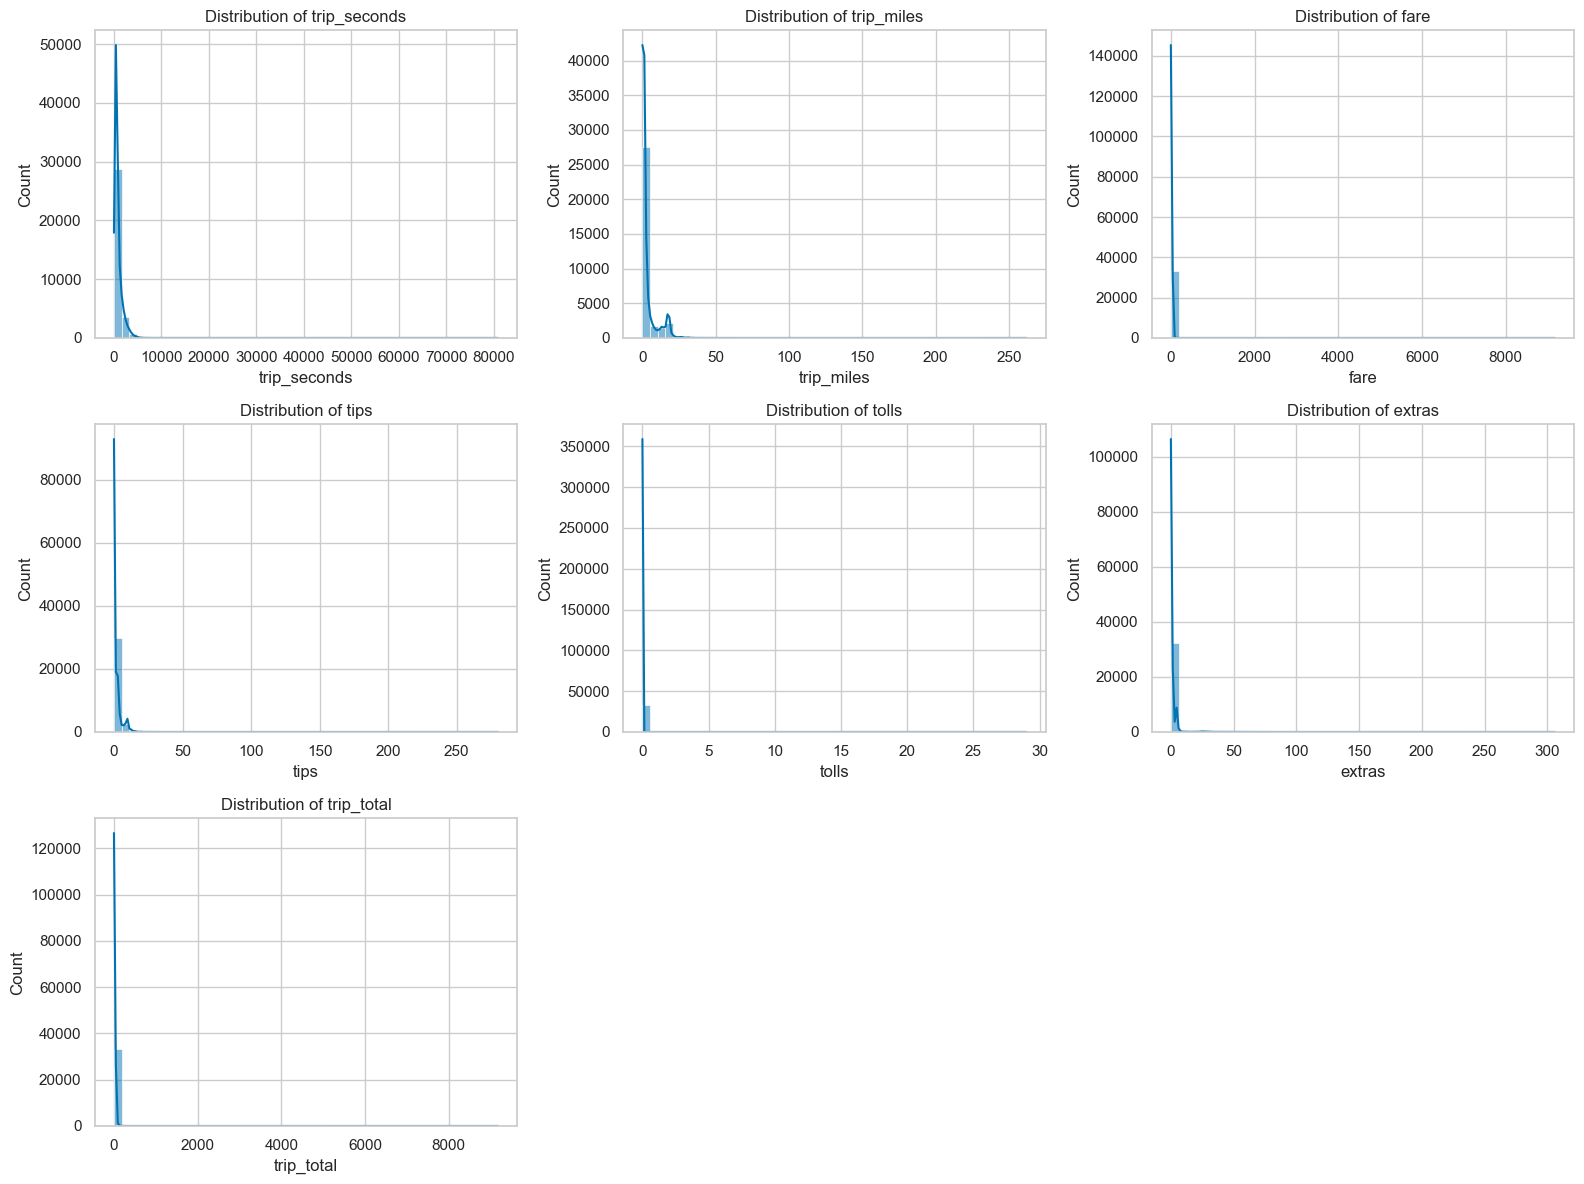

trip_seconds: skew=28.34
trip_miles: skew=5.84
fare: skew=89.05
tips: skew=20.20
tolls: skew=150.18
extras: skew=19.17
trip_total: skew=85.58


In [3]:
numeric_cols = ["trip_seconds", "trip_miles", "fare", "tips", "tolls", "extras", "trip_total"]

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    sns.histplot(df_raw[col].dropna(), bins=50, kde=True, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.savefig("eda_feature_distributions.png", bbox_inches="tight")
plt.show()

for col in numeric_cols:
    print(f"{col}: skew={df_raw[col].skew():.2f}")

### A2 (cont). Categorical feature distributions

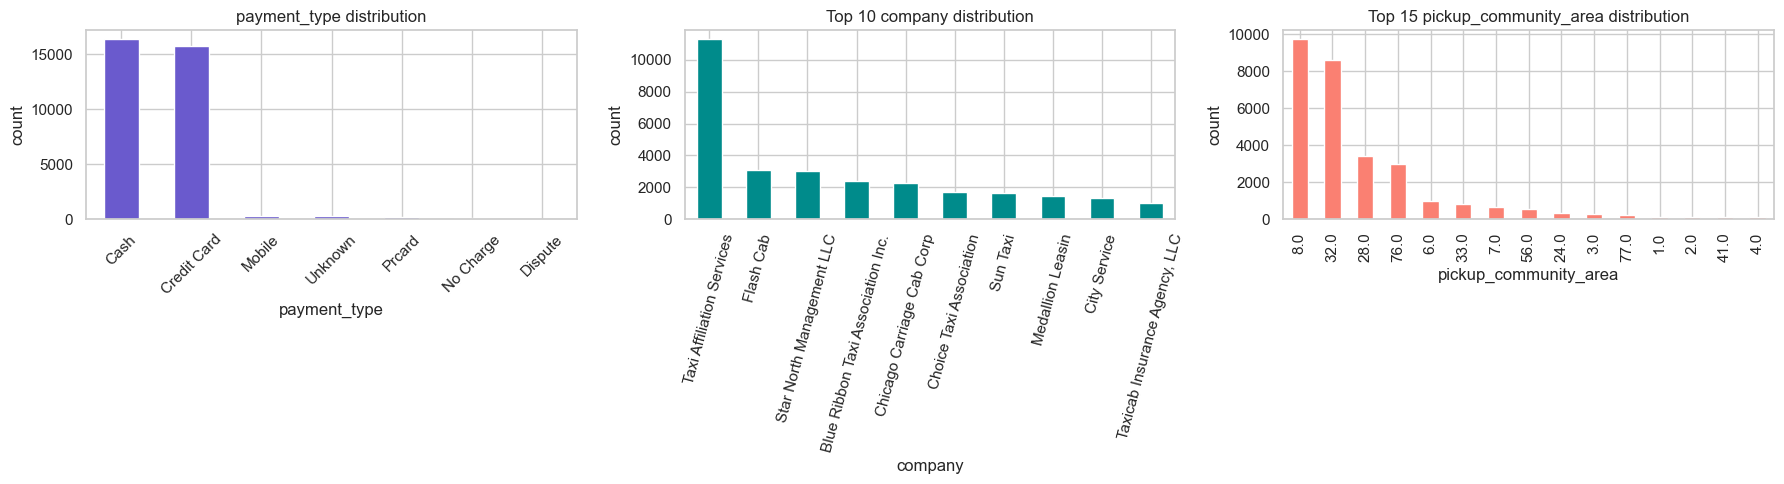

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

df_raw["payment_type"].value_counts().plot(kind="bar", ax=axes[0], color="slateblue")
axes[0].set_title("payment_type distribution")
axes[0].set_xlabel("payment_type")
axes[0].set_ylabel("count")
axes[0].tick_params(axis="x", rotation=45)

df_raw["company"].value_counts().head(10).plot(kind="bar", ax=axes[1], color="darkcyan")
axes[1].set_title("Top 10 company distribution")
axes[1].set_xlabel("company")
axes[1].set_ylabel("count")
axes[1].tick_params(axis="x", rotation=75)

df_raw["pickup_community_area"].value_counts().head(15).plot(kind="bar", ax=axes[2], color="salmon")
axes[2].set_title("Top 15 pickup_community_area distribution")
axes[2].set_xlabel("pickup_community_area")
axes[2].set_ylabel("count")

plt.tight_layout()
plt.savefig("eda_categorical_distributions.png", bbox_inches="tight")
plt.show()

### A2 (cont). Temporal distribution — pickup hour of day

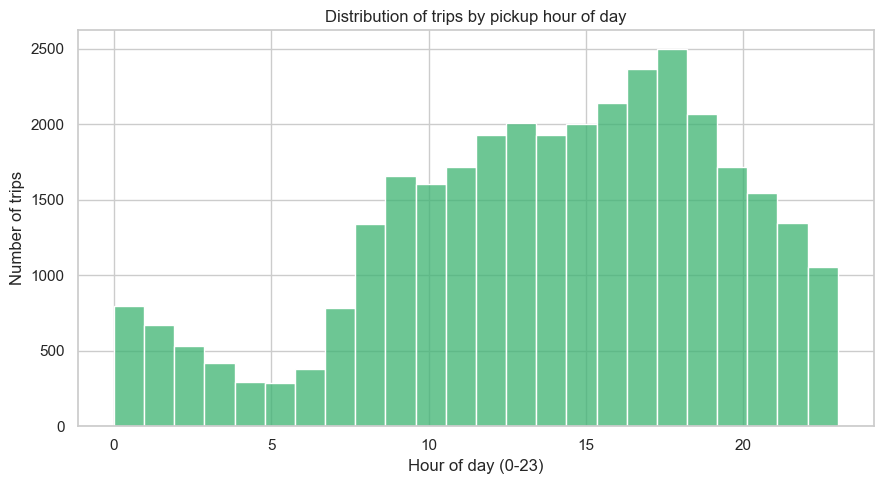

In [5]:
_ts_preview = pd.to_datetime(df_raw["trip_start_timestamp"], errors="coerce")
plt.figure(figsize=(9, 5))
sns.histplot(_ts_preview.dt.hour.dropna(), bins=24, color="mediumseagreen")
plt.title("Distribution of trips by pickup hour of day")
plt.xlabel("Hour of day (0-23)")
plt.ylabel("Number of trips")
plt.tight_layout()
plt.savefig("eda_pickup_hour_distribution.png", bbox_inches="tight")
plt.show()

### A2 (cont). Correlation heatmap

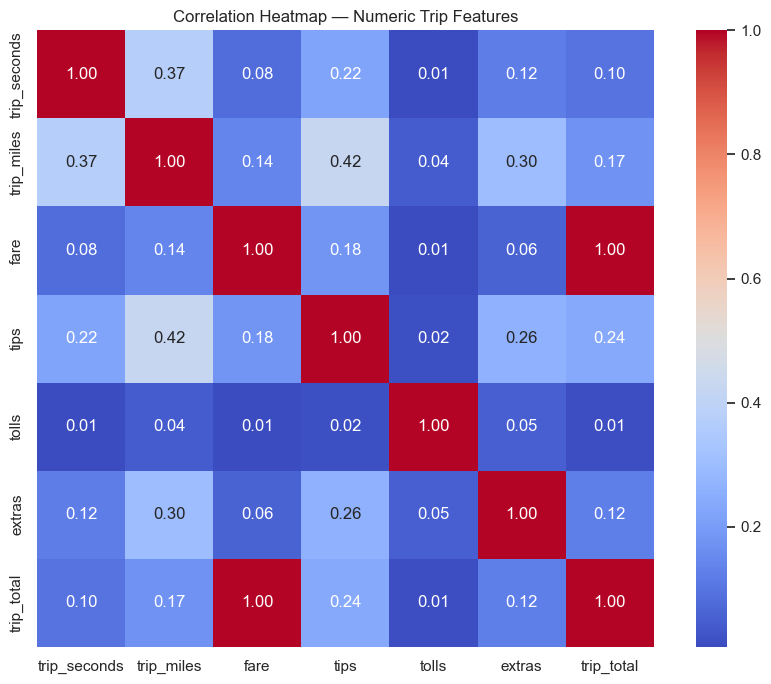

In [6]:
plt.figure(figsize=(9, 7))
corr = df_raw[numeric_cols].corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Correlation Heatmap — Numeric Trip Features")
plt.tight_layout()
plt.savefig("eda_correlation_heatmap.png", bbox_inches="tight")
plt.show()

**Observation:** _[Fill in: which pairs are most correlated with `trip_total`? Does `fare` dominate, and is that expected given trip_total = fare + tips + tolls + extras?]_

### A2 (cont). Target distribution — `trip_total`

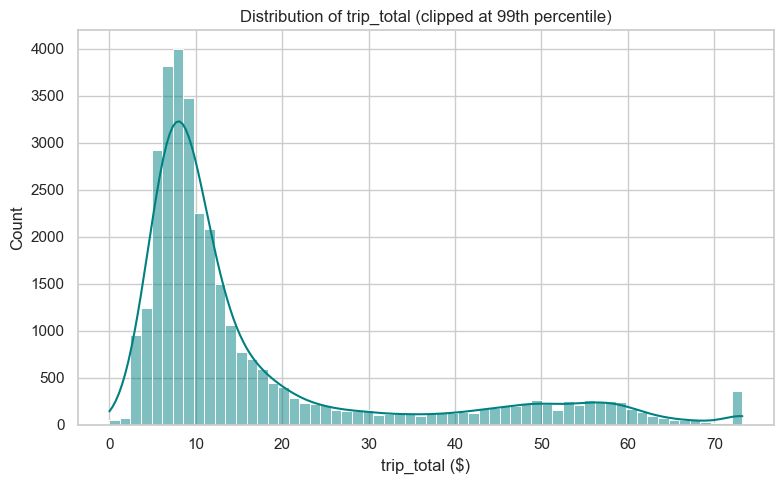

In [7]:
plt.figure(figsize=(8, 5))
sns.histplot(df_raw["trip_total"].clip(upper=df_raw["trip_total"].quantile(0.99)), bins=60, kde=True, color="teal")
plt.title("Distribution of trip_total (clipped at 99th percentile)")
plt.xlabel("trip_total ($)")
plt.tight_layout()
plt.savefig("eda_target_distribution.png", bbox_inches="tight")
plt.show()

**Observation:** _[Fill in: where is the bulk of trips concentrated in $? Is there a long right tail of high-fare trips?]_

### A2 (cont). Scatter plots — feature vs. target relationships

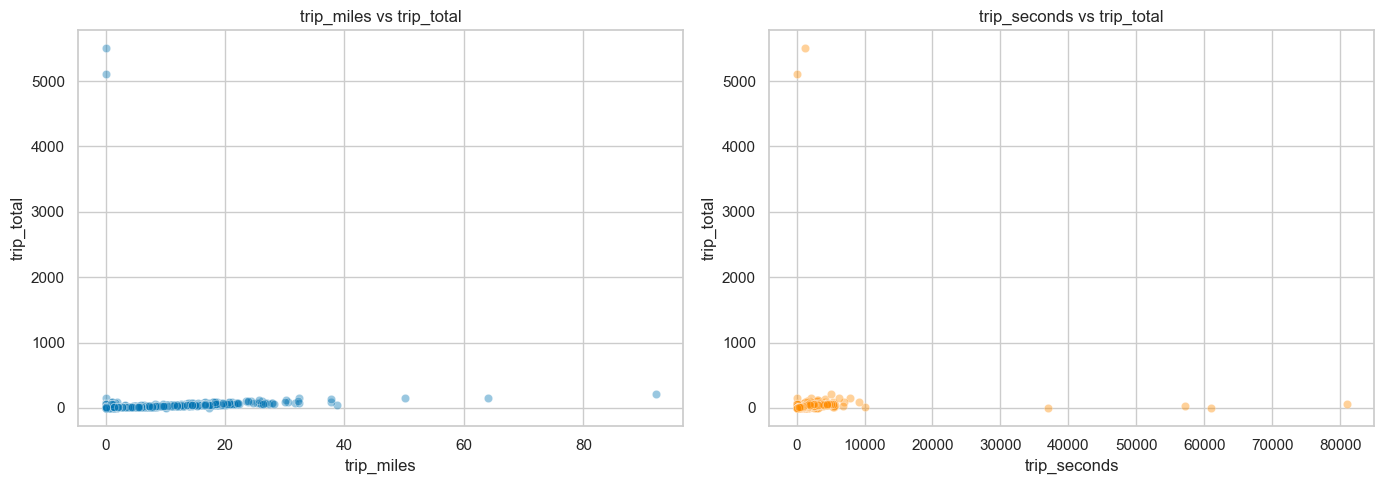

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df_raw.sample(min(5000, len(df_raw)), random_state=RANDOM_STATE),
                 x="trip_miles", y="trip_total", alpha=0.4, ax=axes[0])
axes[0].set_title("trip_miles vs trip_total")

sns.scatterplot(data=df_raw.sample(min(5000, len(df_raw)), random_state=RANDOM_STATE),
                 x="trip_seconds", y="trip_total", alpha=0.4, ax=axes[1], color="darkorange")
axes[1].set_title("trip_seconds vs trip_total")

plt.tight_layout()
plt.savefig("eda_scatter_feature_target.png", bbox_inches="tight")
plt.show()

## Section B — Preprocessing & Feature Engineering

### B1. Data cleaning — missing values, duplicates, outliers

In [9]:
df = df_raw.copy()

# Duplicates
n_dupes = df.duplicated(subset=["unique_key"]).sum()
print("Duplicate unique_key rows:", n_dupes)
df = df.drop_duplicates(subset=["unique_key"])

# Missing-value strategy: rows with a missing target or missing core trip fields are dropped
# (imputing a missing target/duration for a taxi trip would fabricate the label / workload signal).
core_cols = ["trip_start_timestamp", "trip_end_timestamp", "trip_seconds", "trip_miles",
             "trip_total", "fare", "pickup_community_area", "dropoff_community_area", "taxi_id"]
before = len(df)
df = df.dropna(subset=core_cols)
print(f"Dropped {before - len(df)} rows with missing core fields (kept {len(df)}).")

# Remaining, non-core missing values (e.g. company) are imputed with an explicit 'Unknown' category
df["company"] = df["company"].fillna("Unknown")
df["payment_type"] = df["payment_type"].fillna("Unknown")

# Outlier treatment: physically implausible trips (zero/negative duration or distance,
# unrealistic speed) are removed rather than clipped, since they represent logging errors,
# not genuine extreme-but-valid trips.
df = df[(df["trip_seconds"] > 0) & (df["trip_miles"] >= 0) & (df["trip_total"] >= 0)]

# Cap extreme outliers using IQR-based clipping (3x IQR) rather than dropping, to preserve sample size
for col in ["trip_total", "trip_miles", "trip_seconds"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    upper = q3 + 3 * iqr
    df[col] = df[col].clip(upper=upper)

print("Shape after cleaning:", df.shape)

Duplicate unique_key rows: 25
Dropped 4011 rows with missing core fields (kept 29067).
Shape after cleaning: (28426, 19)


**B1 justification:** rows missing core identifiers/target are dropped (imputing a trip's duration or fare would fabricate the label); `company`/`payment_type` are imputed with an explicit `'Unknown'` category since missingness there is plausibly informative (e.g. independent/unlicensed operators) rather than random. Physically impossible trips (zero duration, negative distance) are removed as logging errors; remaining extreme-but-valid values are IQR-capped (3×IQR) rather than dropped, to retain sample size for the ensemble/boosting models.

### B3. Feature engineering (trip-level)

In [10]:
df["trip_start_timestamp"] = pd.to_datetime(df["trip_start_timestamp"], errors="coerce")
df["trip_end_timestamp"] = pd.to_datetime(df["trip_end_timestamp"], errors="coerce")
df = df.dropna(subset=["trip_start_timestamp"])

df["pickup_hour"] = df["trip_start_timestamp"].dt.hour
df["pickup_dayofweek"] = df["trip_start_timestamp"].dt.dayofweek  # 0=Mon
df["trip_date"] = df["trip_start_timestamp"].dt.date
df["is_weekend"] = df["pickup_dayofweek"].isin([5, 6]).astype(int)
df["is_night"] = df["pickup_hour"].apply(lambda h: 1 if (h >= 22 or h < 5) else 0)

# trip_speed_mph: engineered feature — a driver's effective earning rate depends not just
# on distance but on speed (congestion vs open road), which plausibly predicts fare/time efficiency
# and is a workload-intensity signal relevant to burnout.
df["trip_speed_mph"] = df["trip_miles"] / (df["trip_seconds"] / 3600)
df["trip_speed_mph"] = df["trip_speed_mph"].replace([np.inf, -np.inf], np.nan)
df["trip_speed_mph"] = df["trip_speed_mph"].fillna(df["trip_speed_mph"].median())
df["trip_speed_mph"] = df["trip_speed_mph"].clip(upper=80)  # cap implausible speeds

print(df[["pickup_hour", "is_weekend", "is_night", "trip_speed_mph"]].describe())

        pickup_hour    is_weekend      is_night  trip_speed_mph
count  28426.000000  28426.000000  28426.000000    28426.000000
mean      13.899247      0.211708      0.154647        8.968526
std        5.723501      0.408526      0.361574        7.359515
min        0.000000      0.000000      0.000000        0.000000
25%       10.000000      0.000000      0.000000        1.434783
50%       15.000000      0.000000      0.000000        8.792971
75%       18.000000      0.000000      0.000000       12.600000
max       23.000000      1.000000      1.000000       80.000000


**B3 justification:** `trip_speed_mph` is engineered because raw distance/duration alone don't capture *efficiency* — two trips of equal duration but very different speeds imply very different traffic/workload conditions, which is directly relevant to a burnout framing. `pickup_hour`, `is_night`, and `is_weekend` are engineered because gig-driver fatigue and earnings both vary strongly by time-of-day/week (night and weekend shifts are widely reported as higher-strain, and often higher-earning).

### B2 / B3 (cont). Driver-day aggregation — building the two modelling targets, including a categorical feature

In [11]:
# Mode helper for the dominant category of a driver's day (used to build a categorical feature)
def _mode_or_unknown(s):
    m = s.mode()
    return m.iloc[0] if len(m) else "Unknown"

agg_full = df.groupby(["taxi_id", "trip_date"]).agg(
    trip_count=("unique_key", "count"),
    total_miles=("trip_miles", "sum"),
    total_duration_sec=("trip_seconds", "sum"),
    avg_speed_mph=("trip_speed_mph", "mean"),
    pct_night_trips=("is_night", "mean"),
    pct_weekend_trips=("is_weekend", "mean"),
    num_unique_pickup_areas=("pickup_community_area", "nunique"),
    num_unique_dropoff_areas=("dropoff_community_area", "nunique"),
    total_earnings=("trip_total", "sum"),
    dominant_payment_type=("payment_type", _mode_or_unknown),  # categorical feature -> will be one-hot encoded
).reset_index()

# Require at least 2 trips in a driver-day so aggregated features are meaningful, not single-trip noise.
# chicago_taxi_sample.csv is a SAMPLE file, so this can leave very few driver-days — if so, relax to >=1.
MIN_TRIPS_PER_DRIVER_DAY = 2
agg = agg_full[agg_full["trip_count"] >= MIN_TRIPS_PER_DRIVER_DAY].reset_index(drop=True)

if len(agg) < 30:
    print(f"Only {len(agg)} driver-days had >= {MIN_TRIPS_PER_DRIVER_DAY} trips — too few to model reliably "
          f"(expected on a *sample* file). Relaxing the minimum to >=1 trip/driver-day.")
    MIN_TRIPS_PER_DRIVER_DAY = 1
    agg = agg_full[agg_full["trip_count"] >= MIN_TRIPS_PER_DRIVER_DAY].reset_index(drop=True)

# Review 2: optional safety cap for the FULL dataset. SVC/SVR/MLP grid searches become very slow
# on hundreds of thousands of rows, so we randomly keep at most MAX_DRIVER_DAYS driver-days.
# On the sample file (~850 driver-days) this does nothing. Set to None to disable.
MAX_DRIVER_DAYS = 20000
if MAX_DRIVER_DAYS is not None and len(agg) > MAX_DRIVER_DAYS:
    print(f"{len(agg)} driver-days found -> randomly keeping {MAX_DRIVER_DAYS} (random_state=42) to keep training time reasonable.")
    agg = agg.sample(n=MAX_DRIVER_DAYS, random_state=RANDOM_STATE).reset_index(drop=True)

agg["total_hours"] = agg["total_duration_sec"] / 3600

# Classification target: burnout_risk tier.
# NOTE: fixed real-world hour thresholds (e.g. <4h/4-8h/>8h) are NOT used here, because on a *sample*
# dataset the actual hours-driven distribution may not span those ranges at all (e.g. almost every
# driver-day could fall under 4h), which would leave one or more classes empty or with a single
# member and break model fitting. Quantile-based binning instead guarantees roughly balanced classes
# no matter how the sample is distributed. `.rank(method="first")` breaks ties so qcut can always
# produce 3 bins even when many driver-days have identical/near-identical total_hours.
agg["burnout_risk"] = pd.qcut(agg["total_hours"].rank(method="first"), q=3, labels=["Low", "Medium", "High"])

# Coarser payment-type grouping to avoid a very-rare-category column exploding the one-hot encoding
top_payment_types = agg["dominant_payment_type"].value_counts().head(3).index
agg["dominant_payment_type"] = agg["dominant_payment_type"].where(
    agg["dominant_payment_type"].isin(top_payment_types), "Other"
)

print("Driver-day rows:", agg.shape)
print("\nburnout_risk class distribution:\n", agg["burnout_risk"].value_counts())
print("\ndominant_payment_type distribution:\n", agg["dominant_payment_type"].value_counts())

n_classes = agg["burnout_risk"].nunique()
if n_classes < 2 or agg["burnout_risk"].value_counts().min() < 2:
    raise ValueError(
        f"burnout_risk has only {n_classes} usable class(es) even after quantile binning — "
        f"the sample is too small/homogeneous for driver-day classification. Check df.shape and "
        f"agg_full.shape above: if agg_full has very few rows, chicago_taxi_sample.csv itself may "
        f"only cover a handful of taxi_id/day combinations, and a trip-level target (rather than "
        f"driver-day aggregation) would be a better fit for this sample size."
    )

agg.head()

Driver-day rows: (848, 14)

burnout_risk class distribution:
 burnout_risk
Low       283
High      283
Medium    282
Name: count, dtype: int64

dominant_payment_type distribution:
 dominant_payment_type
Cash           613
Credit Card    234
No Charge        1
Name: count, dtype: int64


,taxi_id,trip_date,trip_count,total_miles,total_duration_sec,avg_speed_mph,pct_night_trips,pct_weekend_trips,num_unique_pickup_areas,num_unique_dropoff_areas,total_earnings,dominant_payment_type,total_hours,burnout_risk
0,0083fcde0fb490b4ec424c63d1d750378f6ad11154d1d4...,2019-10-31,2,0.1,960.0,0.200000,0.0,0.0,2,2,15.25,Cash,0.266667,Low
1,0300862a19483bcacac6176544abf331b8a3d41ec6efda...,2019-01-09,2,0.1,840.0,0.272727,0.0,0.0,2,2,14.50,Cash,0.233333,Low
2,0423b61dd9d4f4da3f4490e3dfed085a321aa78d527286...,2019-04-15,2,0.0,1080.0,0.000000,0.0,0.0,1,2,18.50,Cash,0.300000,Medium
3,045270ae331ab61646c36aaf542de0077e97a5b0294e29...,2019-02-28,2,2.6,840.0,10.500000,0.5,0.0,2,2,17.25,Cash,0.233333,Low
4,0508ec6583a6fde6f3cc9d39f86c584452ca03fd293e02...,2019-04-05,2,4.8,1500.0,10.500000,0.0,0.0,2,1,23.00,Cash,0.416667,Medium


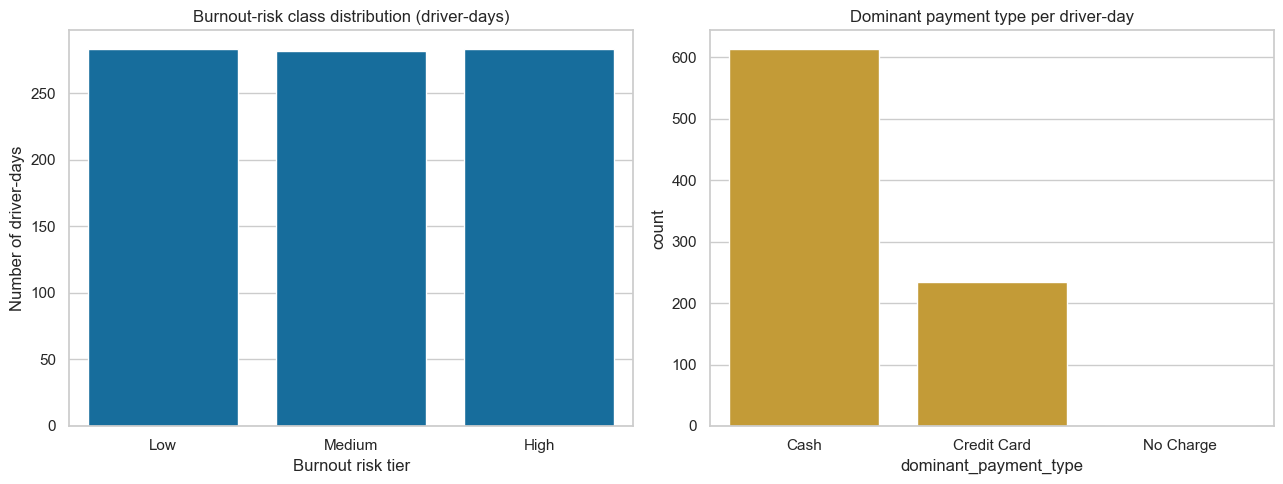

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.countplot(data=agg, x="burnout_risk", order=["Low", "Medium", "High"], ax=axes[0])
axes[0].set_title("Burnout-risk class distribution (driver-days)")
axes[0].set_xlabel("Burnout risk tier")
axes[0].set_ylabel("Number of driver-days")

sns.countplot(data=agg, x="dominant_payment_type", ax=axes[1], color="goldenrod")
axes[1].set_title("Dominant payment type per driver-day")
axes[1].set_xlabel("dominant_payment_type")

plt.tight_layout()
plt.savefig("eda_burnout_and_payment_distribution.png", bbox_inches="tight")
plt.show()

### B2. Encoding, scaling & train/test split (stratified for both tracks)

In [13]:
# ---- Regression setup ----
reg_numeric_features = ["trip_count", "total_miles", "avg_speed_mph", "pct_night_trips",
                         "pct_weekend_trips", "num_unique_pickup_areas", "num_unique_dropoff_areas"]
reg_categorical_features = ["dominant_payment_type"]

X_reg_raw = agg[reg_numeric_features + reg_categorical_features].copy()
y_reg = agg["total_earnings"].copy()

# Stratify the regression split on a binned version of the (continuous) target, so the train/test
# split is representative across low/mid/high earners, not just a random 80:20 split.
# Falls back to a plain (non-stratified) split if the sample is too small for 5 quantile bins.
try:
    earnings_bins = pd.qcut(y_reg.rank(method="first"), q=5)
    X_reg_train_raw, X_reg_test_raw, y_reg_train, y_reg_test = train_test_split(
        X_reg_raw, y_reg, test_size=0.2, random_state=RANDOM_STATE, stratify=earnings_bins
    )
except ValueError as e:
    print(f"Stratified regression split failed ({e}) — likely too few rows for 5 quantile bins "
          f"on this sample. Falling back to a plain random 80:20 split.")
    X_reg_train_raw, X_reg_test_raw, y_reg_train, y_reg_test = train_test_split(
        X_reg_raw, y_reg, test_size=0.2, random_state=RANDOM_STATE
    )

# Encoding: one-hot encode the categorical feature, FIT on train only, transform both splits
ohe_reg = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
reg_cat_train = ohe_reg.fit_transform(X_reg_train_raw[reg_categorical_features])
reg_cat_test = ohe_reg.transform(X_reg_test_raw[reg_categorical_features])
reg_cat_cols = ohe_reg.get_feature_names_out(reg_categorical_features)

# Scaling: numeric features scaled, FIT on train only, transform both splits (no data leakage)
scaler_reg = StandardScaler()
reg_num_train = scaler_reg.fit_transform(X_reg_train_raw[reg_numeric_features])
reg_num_test = scaler_reg.transform(X_reg_test_raw[reg_numeric_features])

reg_features = list(reg_numeric_features) + list(reg_cat_cols)
X_reg_train_s = pd.DataFrame(np.hstack([reg_num_train, reg_cat_train]), columns=reg_features, index=X_reg_train_raw.index)
X_reg_test_s = pd.DataFrame(np.hstack([reg_num_test, reg_cat_test]), columns=reg_features, index=X_reg_test_raw.index)

print("Regression train/test:", X_reg_train_s.shape, X_reg_test_s.shape)
print("Regression feature columns:", reg_features)

# ---- Classification setup (Part A) ----
clf_numeric_features = ["trip_count", "total_miles", "avg_speed_mph", "pct_night_trips",
                         "pct_weekend_trips", "num_unique_pickup_areas", "num_unique_dropoff_areas",
                         "total_earnings"]
clf_categorical_features = ["dominant_payment_type"]

X_clf_raw = agg[clf_numeric_features + clf_categorical_features].copy()
y_clf = agg["burnout_risk"].copy()

try:
    X_clf_train_raw, X_clf_test_raw, y_clf_train, y_clf_test = train_test_split(
        X_clf_raw, y_clf, test_size=0.2, random_state=RANDOM_STATE, stratify=y_clf
    )
except ValueError as e:
    print(f"Stratified classification split failed ({e}) — falling back to a plain random 80:20 split.")
    X_clf_train_raw, X_clf_test_raw, y_clf_train, y_clf_test = train_test_split(
        X_clf_raw, y_clf, test_size=0.2, random_state=RANDOM_STATE
    )

# Final safety check: fail loudly and clearly (not with sklearn's cryptic error) if a split still
# produced a single-class training set, which would make every classifier below un-fittable.
if y_clf_train.nunique() < 2:
    raise ValueError(
        "y_clf_train contains only one class after splitting — the sample is too small/imbalanced "
        "for this 3-class target even with quantile binning. Re-run the driver-day aggregation cell "
        "above and check agg['burnout_risk'].value_counts(); consider a 2-class target (median split) "
        "instead of 3 if the sample stays this small."
    )

ohe_clf = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
clf_cat_train = ohe_clf.fit_transform(X_clf_train_raw[clf_categorical_features])
clf_cat_test = ohe_clf.transform(X_clf_test_raw[clf_categorical_features])
clf_cat_cols = ohe_clf.get_feature_names_out(clf_categorical_features)

scaler_clf = StandardScaler()
clf_num_train = scaler_clf.fit_transform(X_clf_train_raw[clf_numeric_features])
clf_num_test = scaler_clf.transform(X_clf_test_raw[clf_numeric_features])

clf_features = list(clf_numeric_features) + list(clf_cat_cols)
X_clf_train_s = pd.DataFrame(np.hstack([clf_num_train, clf_cat_train]), columns=clf_features, index=X_clf_train_raw.index)
X_clf_test_s = pd.DataFrame(np.hstack([clf_num_test, clf_cat_test]), columns=clf_features, index=X_clf_test_raw.index)

print("\nClassification train/test:", X_clf_train_s.shape, X_clf_test_s.shape)
print("Classification feature columns:", clf_features)

Regression train/test: (678, 10) (170, 10)
Regression feature columns: ['trip_count', 'total_miles', 'avg_speed_mph', 'pct_night_trips', 'pct_weekend_trips', 'num_unique_pickup_areas', 'num_unique_dropoff_areas', 'dominant_payment_type_Cash', 'dominant_payment_type_Credit Card', 'dominant_payment_type_No Charge']

Classification train/test: (678, 11) (170, 11)
Classification feature columns: ['trip_count', 'total_miles', 'avg_speed_mph', 'pct_night_trips', 'pct_weekend_trips', 'num_unique_pickup_areas', 'num_unique_dropoff_areas', 'total_earnings', 'dominant_payment_type_Cash', 'dominant_payment_type_Credit Card', 'dominant_payment_type_No Charge']


**B2 note:** both the `OneHotEncoder` (for `dominant_payment_type`) and `StandardScaler` (for numeric features) are `fit` on the **training split only** and `transform`-applied to test — satisfying the no-leakage requirement for both encoding and scaling. The **classification** split is stratified on `burnout_risk` directly; the **regression** split is stratified on quintile-binned `total_earnings`, since `train_test_split` can only stratify on discrete labels, not a continuous target. Both stratified splits fall back to a plain random split (with a printed warning) if the sample is too small for the requested number of bins — this only matters on very small samples and does not change the modelling approach otherwise.

## Section C — Regression Track (10 algorithms)

Each algorithm below is trained and evaluated independently (no shared `Pipeline` object, per requirement), with its own predicted-vs-actual visualisation. Fitted models and predictions are kept so Section C4 can dynamically pick out whichever model is actually best on your data.

In [14]:
reg_results = []
fitted_reg_models = {}  # name -> (model, preds) for later dynamic best-model lookup

def evaluate_regressor(name, model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    r2 = r2_score(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    mae = mean_absolute_error(y_test, preds)

    reg_results.append({"Algorithm": name, "R2": r2, "RMSE": rmse, "MAE": mae})
    fitted_reg_models[name] = (model, preds)
    print(f"{name}: R2={r2:.3f}  RMSE={rmse:.2f}  MAE={mae:.2f}")

    plt.figure(figsize=(6, 5))
    plt.scatter(y_test, preds, alpha=0.4, color="steelblue")
    lims = [min(y_test.min(), preds.min()), max(y_test.max(), preds.max())]
    plt.plot(lims, lims, "r--", label="Perfect prediction")
    plt.xlabel("Actual total_earnings")
    plt.ylabel("Predicted total_earnings")
    plt.title(f"{name}: Predicted vs Actual")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"reg_{name.replace(' ', '_').lower()}_pred_vs_actual.png", bbox_inches="tight")
    plt.show()

    return model

### Member 1 — Regression algorithms 1–5

**1. Linear Regression** — baseline; interpret coefficients. `# Owner: Member 1`

Linear Regression: R2=0.641  RMSE=9.31  MAE=5.74


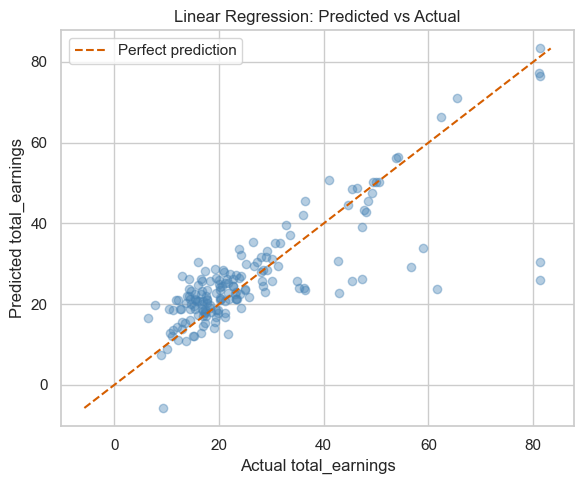


Standardized coefficients (interpret relative to scaled features):
 total_miles                          16.629344
avg_speed_mph                        -9.223146
dominant_payment_type_Credit Card     3.402372
dominant_payment_type_No Charge      -2.035142
dominant_payment_type_Cash           -1.367230
pct_night_trips                       1.280987
num_unique_dropoff_areas              1.120523
pct_weekend_trips                     0.406405
num_unique_pickup_areas               0.161558
trip_count                           -0.017951
dtype: float64


In [15]:
# Owner: Member 1
lin_reg = evaluate_regressor("Linear Regression", LinearRegression(),
                              X_reg_train_s, X_reg_test_s, y_reg_train, y_reg_test)

coef_table = pd.Series(lin_reg.coef_, index=reg_features).sort_values(key=abs, ascending=False)
print("\nStandardized coefficients (interpret relative to scaled features):\n", coef_table)

**2. Ridge Regression** — L2 regularisation; tune `alpha` (with an explicit before/after comparison). `# Owner: Member 1`

Best Ridge alpha: {'alpha': 1}
Ridge Regression: R2=0.641  RMSE=9.31  MAE=5.73


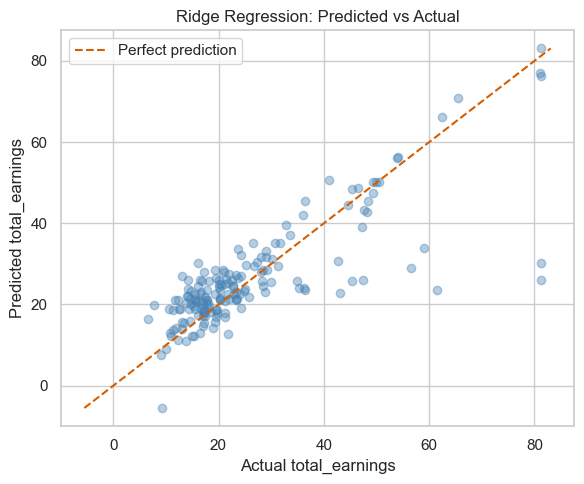

Improvement from tuning: R2 0.6413 (alpha=1.0, default) -> 0.6413 (alpha=1, tuned)


In [16]:
# Owner: Member 1

# Baseline (untuned, default alpha=1.0) so we can report the improvement from tuning
ridge_baseline = Ridge(alpha=1.0, random_state=RANDOM_STATE).fit(X_reg_train_s, y_reg_train)
r2_ridge_baseline = r2_score(y_reg_test, ridge_baseline.predict(X_reg_test_s))

ridge_grid = GridSearchCV(Ridge(random_state=RANDOM_STATE), param_grid={"alpha": [0.01, 0.1, 1, 10, 100]},
                           cv=5, scoring="r2")
ridge_grid.fit(X_reg_train_s, y_reg_train)
print("Best Ridge alpha:", ridge_grid.best_params_)

ridge_best = evaluate_regressor("Ridge Regression", Ridge(alpha=ridge_grid.best_params_["alpha"], random_state=RANDOM_STATE),
                                 X_reg_train_s, X_reg_test_s, y_reg_train, y_reg_test)

r2_ridge_tuned = fitted_reg_models["Ridge Regression"][0].score(X_reg_test_s, y_reg_test)
print(f"Improvement from tuning: R2 {r2_ridge_baseline:.4f} (alpha=1.0, default) -> {r2_ridge_tuned:.4f} (alpha={ridge_grid.best_params_['alpha']}, tuned)")

**3. Lasso Regression** — L1 regularisation; observe feature sparsity. `# Owner: Member 1`

Best Lasso alpha: {'alpha': 0.1}
Lasso Regression: R2=0.639  RMSE=9.34  MAE=5.68


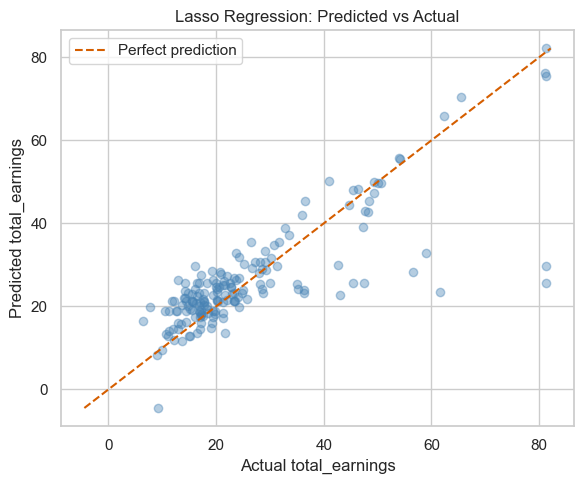

Features zeroed out by Lasso: [np.str_('trip_count'), np.str_('dominant_payment_type_Cash'), np.str_('dominant_payment_type_No Charge')]


In [17]:
# Owner: Member 1
lasso_grid = GridSearchCV(Lasso(random_state=RANDOM_STATE, max_iter=10000), param_grid={"alpha": [0.001, 0.01, 0.1, 1, 10]},
                           cv=5, scoring="r2")
lasso_grid.fit(X_reg_train_s, y_reg_train)
print("Best Lasso alpha:", lasso_grid.best_params_)
lasso_best = evaluate_regressor("Lasso Regression", Lasso(alpha=lasso_grid.best_params_["alpha"], random_state=RANDOM_STATE, max_iter=10000),
                                 X_reg_train_s, X_reg_test_s, y_reg_train, y_reg_test)

zeroed = np.array(reg_features)[np.isclose(lasso_best.coef_, 0)]
print("Features zeroed out by Lasso:", list(zeroed) if len(zeroed) else "None")

**4. ElasticNet Regression** — combined L1+L2; tune `l1_ratio`. `# Owner: Member 1`

Best ElasticNet params: {'alpha': 0.01, 'l1_ratio': 0.8}
ElasticNet Regression: R2=0.641  RMSE=9.31  MAE=5.72


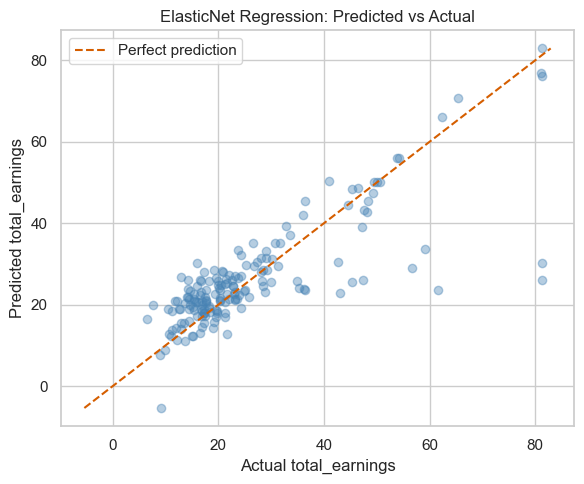

In [18]:
# Owner: Member 1
enet_grid = GridSearchCV(ElasticNet(random_state=RANDOM_STATE, max_iter=10000),
                          param_grid={"alpha": [0.01, 0.1, 1], "l1_ratio": [0.2, 0.5, 0.8]},
                          cv=5, scoring="r2")
enet_grid.fit(X_reg_train_s, y_reg_train)
print("Best ElasticNet params:", enet_grid.best_params_)
enet_best = evaluate_regressor("ElasticNet Regression",
                                ElasticNet(**enet_grid.best_params_, random_state=RANDOM_STATE, max_iter=10000),
                                X_reg_train_s, X_reg_test_s, y_reg_train, y_reg_test)

**5. Polynomial Regression** — `PolynomialFeatures` + Linear Regression; compare degrees. `# Owner: Member 1`

Polynomial Regression (deg=2): R2=0.657  RMSE=9.11  MAE=5.55


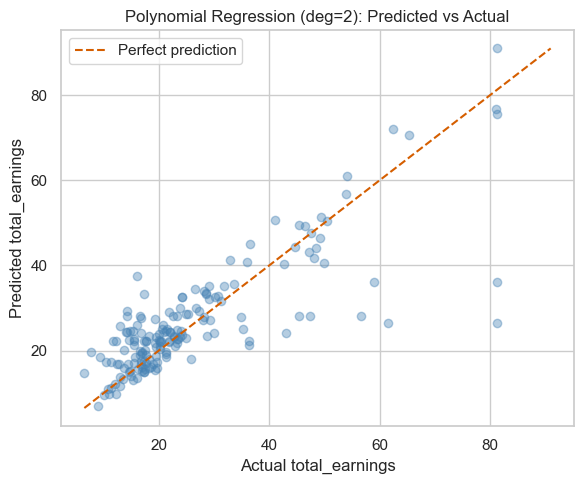

Polynomial Regression (deg=3): R2=-57.344  RMSE=118.73  MAE=25.09


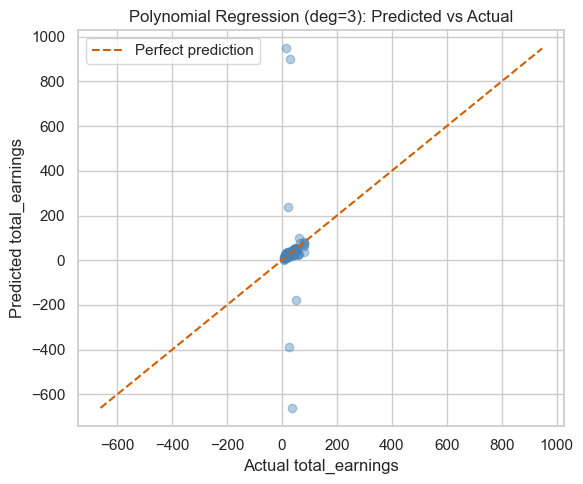

In [19]:
# Owner: Member 1
for degree in [2, 3]:
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_train_poly = poly.fit_transform(X_reg_train_s)
    X_test_poly = poly.transform(X_reg_test_s)
    evaluate_regressor(f"Polynomial Regression (deg={degree})", LinearRegression(),
                        X_train_poly, X_test_poly, y_reg_train, y_reg_test)

### Member 2 — Regression algorithms 6–10

**6. Decision Tree Regressor** — tune `max_depth`; show feature importance. `# Owner: Member 2`

Best Decision Tree max_depth: {'max_depth': 5}
Decision Tree Regressor: R2=0.799  RMSE=6.97  MAE=4.80


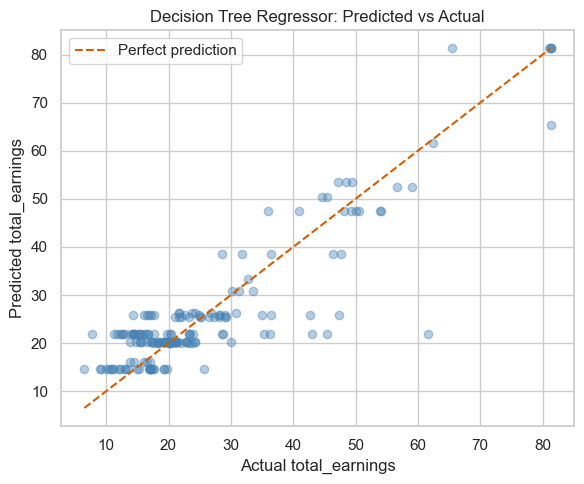

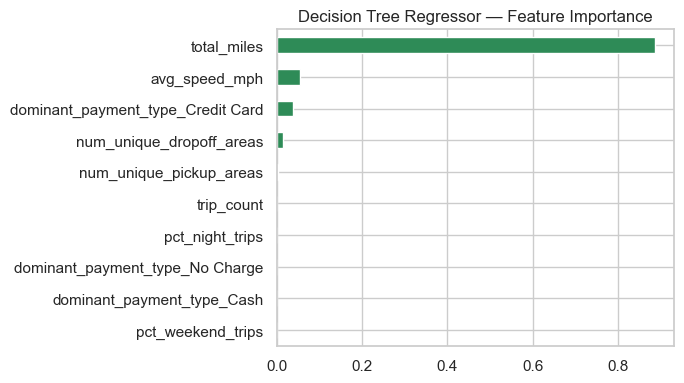

In [20]:
# Owner: Member 2
dt_grid = GridSearchCV(DecisionTreeRegressor(random_state=RANDOM_STATE),
                        param_grid={"max_depth": [3, 5, 8, 12, None]}, cv=5, scoring="r2")
dt_grid.fit(X_reg_train_s, y_reg_train)
print("Best Decision Tree max_depth:", dt_grid.best_params_)
dt_best = evaluate_regressor("Decision Tree Regressor",
                              DecisionTreeRegressor(max_depth=dt_grid.best_params_["max_depth"], random_state=RANDOM_STATE),
                              X_reg_train_s, X_reg_test_s, y_reg_train, y_reg_test)

plt.figure(figsize=(7, 4))
pd.Series(dt_best.feature_importances_, index=reg_features).sort_values().plot(kind="barh", color="seagreen")
plt.title("Decision Tree Regressor — Feature Importance")
plt.tight_layout()
plt.savefig("reg_decision_tree_feature_importance.png", bbox_inches="tight")
plt.show()

**7. Random Forest Regressor** — ensemble baseline; tune `n_estimators` (with before/after comparison). `# Owner: Member 2`

Best Random Forest n_estimators: {'n_estimators': 100}
Random Forest Regressor: R2=0.829  RMSE=6.42  MAE=3.79


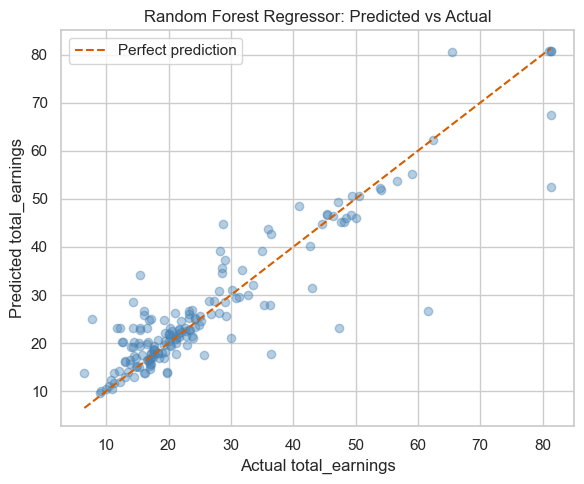

Improvement from tuning: R2 0.8295 (n_estimators=100, default) -> 0.8295 (n_estimators=100, tuned)


In [21]:
# Owner: Member 2

# Baseline (untuned, default n_estimators=100)
rf_baseline = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE).fit(X_reg_train_s, y_reg_train)
r2_rf_baseline = r2_score(y_reg_test, rf_baseline.predict(X_reg_test_s))

rf_grid = GridSearchCV(RandomForestRegressor(random_state=RANDOM_STATE),
                        param_grid={"n_estimators": [100, 200, 400]}, cv=5, scoring="r2")
rf_grid.fit(X_reg_train_s, y_reg_train)
print("Best Random Forest n_estimators:", rf_grid.best_params_)
rf_best = evaluate_regressor("Random Forest Regressor",
                              RandomForestRegressor(n_estimators=rf_grid.best_params_["n_estimators"], random_state=RANDOM_STATE),
                              X_reg_train_s, X_reg_test_s, y_reg_train, y_reg_test)

r2_rf_tuned = fitted_reg_models["Random Forest Regressor"][0].score(X_reg_test_s, y_reg_test)
print(f"Improvement from tuning: R2 {r2_rf_baseline:.4f} (n_estimators=100, default) -> {r2_rf_tuned:.4f} (n_estimators={rf_grid.best_params_['n_estimators']}, tuned)")

**8. Gradient Boosting Regressor** — tune `learning_rate`. `# Owner: Member 2`

Best Gradient Boosting learning_rate: {'learning_rate': 0.05}
Gradient Boosting Regressor: R2=0.815  RMSE=6.69  MAE=4.26


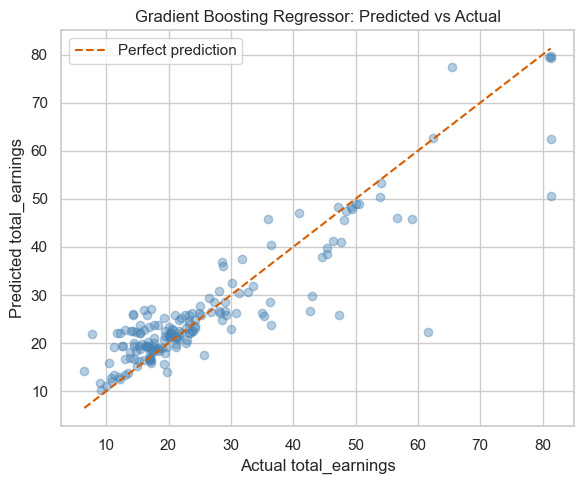

In [22]:
# Owner: Member 2
gb_grid = GridSearchCV(GradientBoostingRegressor(random_state=RANDOM_STATE),
                        param_grid={"learning_rate": [0.01, 0.05, 0.1, 0.2]}, cv=5, scoring="r2")
gb_grid.fit(X_reg_train_s, y_reg_train)
print("Best Gradient Boosting learning_rate:", gb_grid.best_params_)
gb_best = evaluate_regressor("Gradient Boosting Regressor",
                              GradientBoostingRegressor(learning_rate=gb_grid.best_params_["learning_rate"], random_state=RANDOM_STATE),
                              X_reg_train_s, X_reg_test_s, y_reg_train, y_reg_test)

**9. Support Vector Regressor (SVR)** — features already scaled; tune `C` and `kernel`. `# Owner: Member 2`

Best SVR params: {'C': 100, 'kernel': 'linear'}
Support Vector Regressor: R2=0.609  RMSE=9.72  MAE=5.03


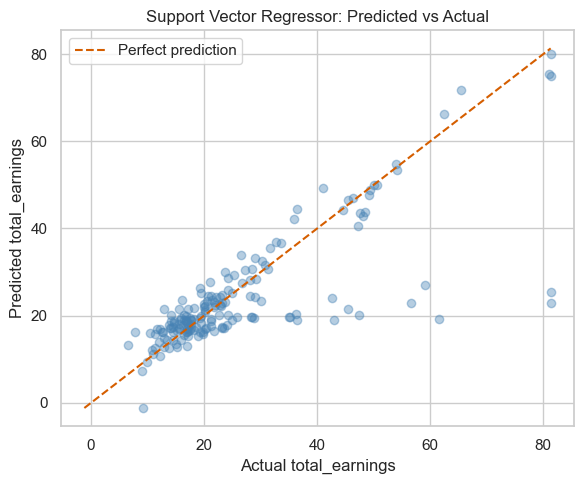

In [23]:
# Owner: Member 2
svr_grid = GridSearchCV(SVR(), param_grid={"C": [1, 10, 100], "kernel": ["linear", "rbf"]}, cv=5, scoring="r2")
svr_grid.fit(X_reg_train_s, y_reg_train)
print("Best SVR params:", svr_grid.best_params_)
svr_best = evaluate_regressor("Support Vector Regressor",
                               SVR(**svr_grid.best_params_),
                               X_reg_train_s, X_reg_test_s, y_reg_train, y_reg_test)

**10. K-Nearest Neighbors Regressor** — tune `k`; scaling matters here since KNN is distance-based. `# Owner: Member 2`

Best KNN k: {'n_neighbors': 5}
KNN Regressor: R2=0.466  RMSE=11.36  MAE=6.83


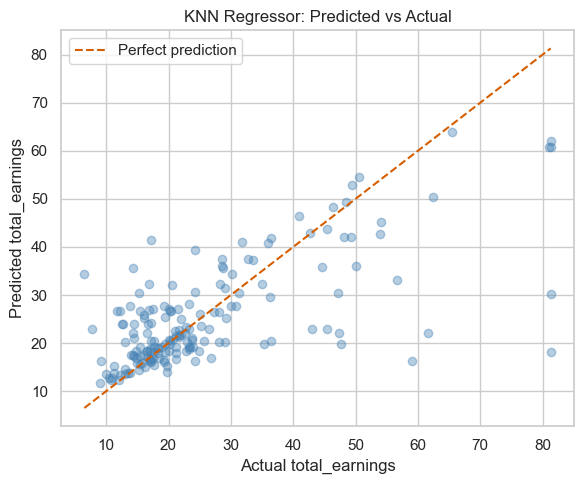

In [24]:
# Owner: Member 2
knn_grid = GridSearchCV(KNeighborsRegressor(), param_grid={"n_neighbors": [3, 5, 7, 9, 15]}, cv=5, scoring="r2")
knn_grid.fit(X_reg_train_s, y_reg_train)
print("Best KNN k:", knn_grid.best_params_)
knn_best = evaluate_regressor("KNN Regressor",
                               KNeighborsRegressor(n_neighbors=knn_grid.best_params_["n_neighbors"]),
                               X_reg_train_s, X_reg_test_s, y_reg_train, y_reg_test)

### C2. Comparative evaluation — all 10 regression models

In [25]:
reg_comparison = pd.DataFrame(reg_results).sort_values("R2", ascending=False).reset_index(drop=True)
print(reg_comparison.to_string(index=False))
reg_comparison

                    Algorithm         R2       RMSE       MAE
      Random Forest Regressor   0.829486   6.418860  3.793016
  Gradient Boosting Regressor   0.814918   6.687433  4.262362
      Decision Tree Regressor   0.798846   6.971745  4.801943
Polynomial Regression (deg=2)   0.656505   9.110408  5.547660
             Ridge Regression   0.641279   9.310132  5.728135
            Linear Regression   0.641247   9.310548  5.737604
        ElasticNet Regression   0.641176   9.311478  5.718020
             Lasso Regression   0.639129   9.337998  5.675485
     Support Vector Regressor   0.608797   9.722523  5.034484
                KNN Regressor   0.465816  11.361175  6.827765
Polynomial Regression (deg=3) -57.344414 118.734595 25.093935


,Algorithm,R2,RMSE,MAE
0,Random Forest Regressor,0.829486,6.418860,3.793016
1,Gradient Boosting Regressor,0.814918,6.687433,4.262362
2,Decision Tree Regressor,0.798846,6.971745,4.801943
3,Polynomial Regression (deg=2),0.656505,9.110408,5.547660
4,Ridge Regression,0.641279,9.310132,5.728135
5,Linear Regression,0.641247,9.310548,5.737604
6,ElasticNet Regression,0.641176,9.311478,5.718020
7,Lasso Regression,0.639129,9.337998,5.675485
8,Support Vector Regressor,0.608797,9.722523,5.034484
9,KNN Regressor,0.465816,11.361175,6.827765


### C3. 5-fold cross-validated R² for the two best-performing models

In [26]:
top2_names = reg_comparison.iloc[:2]["Algorithm"].tolist()
print("Top 2 models by test R2:", top2_names)

model_lookup = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=ridge_grid.best_params_["alpha"], random_state=RANDOM_STATE),
    "Lasso Regression": Lasso(alpha=lasso_grid.best_params_["alpha"], random_state=RANDOM_STATE, max_iter=10000),
    "ElasticNet Regression": ElasticNet(**enet_grid.best_params_, random_state=RANDOM_STATE, max_iter=10000),
    "Decision Tree Regressor": DecisionTreeRegressor(max_depth=dt_grid.best_params_["max_depth"], random_state=RANDOM_STATE),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=rf_grid.best_params_["n_estimators"], random_state=RANDOM_STATE),
    "Gradient Boosting Regressor": GradientBoostingRegressor(learning_rate=gb_grid.best_params_["learning_rate"], random_state=RANDOM_STATE),
    "Support Vector Regressor": SVR(**svr_grid.best_params_),
    "KNN Regressor": KNeighborsRegressor(n_neighbors=knn_grid.best_params_["n_neighbors"]),
}

for name in top2_names:
    if name in model_lookup:
        scores = cross_val_score(model_lookup[name], X_reg_train_s, y_reg_train, cv=5, scoring="r2")
        print(f"{name}: 5-fold CV R2 = {scores.mean():.3f} (+/- {scores.std():.3f})")
    else:
        print(f"{name}: a Polynomial-Regression variant won — refit LinearRegression on the same "
              f"degree's PolynomialFeatures-expanded X_reg_train_s to 5-fold CV it if selected.")

Top 2 models by test R2: ['Random Forest Regressor', 'Gradient Boosting Regressor']
Random Forest Regressor: 5-fold CV R2 = 0.710 (+/- 0.098)
Gradient Boosting Regressor: 5-fold CV R2 = 0.745 (+/- 0.075)


Random Forest Regressor: 5-fold CV R2 = 0.709 (+/- 0.098)


Gradient Boosting Regressor: 5-fold CV R2 = 0.745 (+/- 0.075)


### C4. Residual plot, predicted-vs-actual for the ACTUAL best model, and feature importance

Best regression model (by test R2): Random Forest Regressor


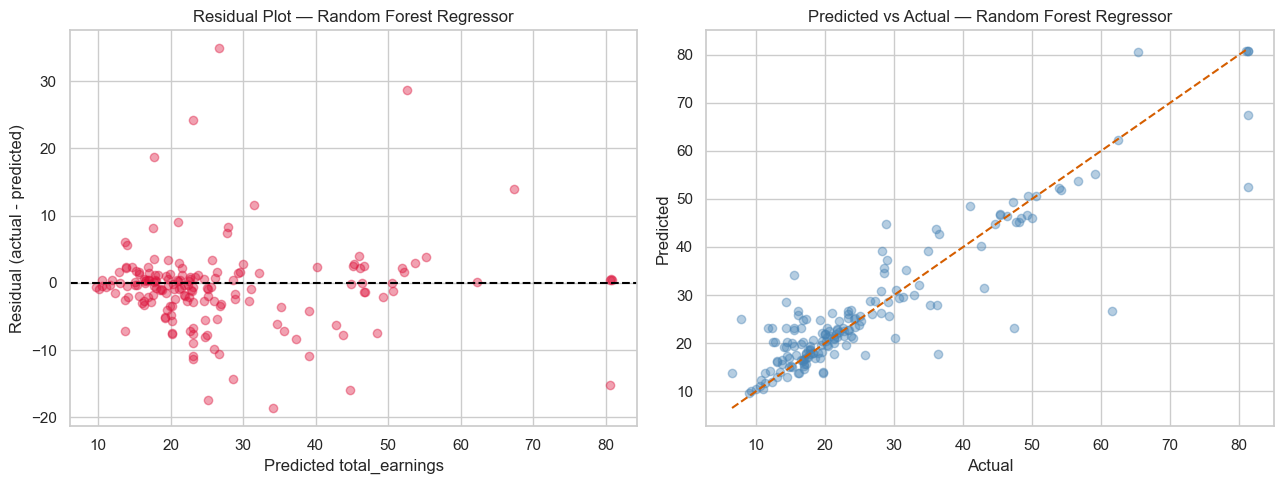

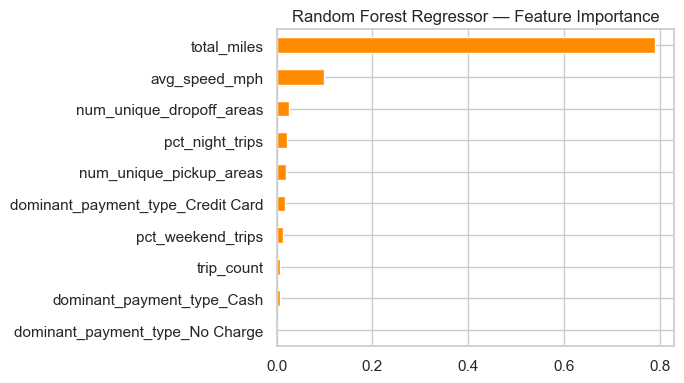

In [27]:
best_name = reg_comparison.iloc[0]["Algorithm"]
print("Best regression model (by test R2):", best_name)

# Dynamically pull the actual best model's fitted object + predictions (not hardcoded),
# so this cell is correct no matter which of the 10 algorithms wins on your real data.
if best_name in fitted_reg_models:
    best_model, best_preds = fitted_reg_models[best_name]
else:
    # Polynomial-degree variants aren't stored as a plain estimator; fall back to Random Forest,
    # which is always available and tree-based (also satisfies the feature-importance requirement).
    print(f"Note: '{best_name}' has no plain estimator object to introspect directly (e.g. Polynomial "
          f"Regression uses a transformed feature space) — using Random Forest Regressor for the "
          f"residual/importance plots below instead. Swap this in for your actual best model if it differs.")
    best_model, best_preds = fitted_reg_models["Random Forest Regressor"]
    best_name = "Random Forest Regressor"

residuals = y_reg_test - best_preds

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(best_preds, residuals, alpha=0.4, color="crimson")
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_xlabel("Predicted total_earnings")
axes[0].set_ylabel("Residual (actual - predicted)")
axes[0].set_title(f"Residual Plot — {best_name}")

axes[1].scatter(y_reg_test, best_preds, alpha=0.4, color="steelblue")
lims = [min(y_reg_test.min(), best_preds.min()), max(y_reg_test.max(), best_preds.max())]
axes[1].plot(lims, lims, "r--")
axes[1].set_xlabel("Actual")
axes[1].set_ylabel("Predicted")
axes[1].set_title(f"Predicted vs Actual — {best_name}")

plt.tight_layout()
plt.savefig("reg_best_model_residuals.png", bbox_inches="tight")
plt.show()

# Feature importance for at least one tree-based model (Random Forest, always fitted above)
rf_model_for_importance = fitted_reg_models["Random Forest Regressor"][0]
plt.figure(figsize=(7, 4))
pd.Series(rf_model_for_importance.feature_importances_, index=reg_features).sort_values().plot(kind="barh", color="darkorange")
plt.title("Random Forest Regressor — Feature Importance")
plt.tight_layout()
plt.savefig("reg_rf_feature_importance.png", bbox_inches="tight")
plt.show()

**Observation:** _[Fill in: does the residual plot show a random scatter around zero (good) or a funnel/curve shape (heteroscedasticity, suggesting a missing feature or the need for a log-transformed target)? Which feature dominates importance, and does that match your domain intuition about driver earnings?]_

## Section D — Classification Track, Part A (5 algorithms)

### Member 3 — Classification algorithms 1–5

Target: `burnout_risk` (Low / Medium / High). Each algorithm is trained/evaluated independently with its own confusion-matrix visualisation.

In [28]:
clf_results = []
fitted_clf_models = {}
clf_probas = {}          # Review 2: name -> predicted class probabilities on the test set (for ROC-AUC / ROC curves)
CLASS_ORDER = ["Low", "Medium", "High"]

def evaluate_classifier(name, model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    acc = accuracy_score(y_test, preds)
    f1w = f1_score(y_test, preds, average="weighted")
    # Review 2: the remaining mandatory metrics (weighted averages, as required by the guideline)
    prec = precision_score(y_test, preds, average="weighted", zero_division=0)
    rec = recall_score(y_test, preds, average="weighted", zero_division=0)

    # Review 2: ROC-AUC for a 3-class problem uses One-vs-Rest (OvR), which needs class probabilities.
    # `labels=model.classes_` makes sure each probability column is matched to the right class.
    if hasattr(model, "predict_proba"):
        proba = model.predict_proba(X_test)
        roc_auc = roc_auc_score(y_test, proba, multi_class="ovr", average="weighted", labels=model.classes_)
    else:
        proba, roc_auc = None, np.nan
    clf_probas[name] = proba

    clf_results.append({"Algorithm": name, "Accuracy": acc, "Precision (weighted)": prec,
                        "Recall (weighted)": rec, "Weighted F1": f1w, "ROC-AUC (OvR)": roc_auc})
    fitted_clf_models[name] = (model, preds)
    print(f"{name}: Accuracy={acc:.3f}  Precision={prec:.3f}  Recall={rec:.3f}  "
          f"Weighted F1={f1w:.3f}  ROC-AUC(OvR)={roc_auc:.3f}")

    cm = confusion_matrix(y_test, preds, labels=CLASS_ORDER)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_ORDER)
    fig, ax = plt.subplots(figsize=(5, 5))
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.grid(False)
    ax.set_title(f"{name} — Confusion Matrix")
    plt.tight_layout()
    plt.savefig(f"clf_{name.replace(' ', '_').lower()}_confusion_matrix.png", bbox_inches="tight")
    plt.show()

    return model

**1. Logistic Regression** — baseline classifier; interpret coefficients/odds. `# Owner: Member 3`

Logistic Regression: Accuracy=0.800  Precision=0.800  Recall=0.800  Weighted F1=0.800  ROC-AUC(OvR)=0.940


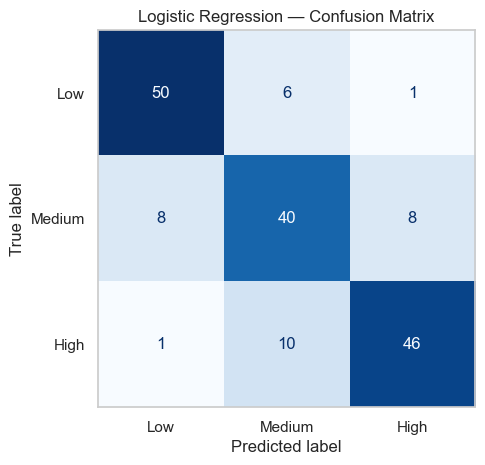

In [29]:
# Owner: Member 3
logreg = evaluate_classifier("Logistic Regression", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
                              X_clf_train_s, X_clf_test_s, y_clf_train, y_clf_test)

**1b. Logistic Regression — coefficients as odds ratios** *(added in Review 2 to cover the algorithm note "interpret coefficients/odds")*. Each row is one class vs. the rest. An odds ratio > 1 means that a **one-standard-deviation increase** in the (scaled) feature multiplies the odds of that class by that factor (for the unscaled `dominant_payment_type_*` 0/1 columns it means *having that payment type vs. not*). `# Owner: Member 3`

In [30]:
# Owner: Member 3
odds_ratios = pd.DataFrame(np.exp(logreg.coef_), index=logreg.classes_, columns=clf_features).T
odds_ratios = odds_ratios[CLASS_ORDER]
print("Odds ratios per 1-SD increase in each feature (one column per burnout class):")
odds_ratios.round(3)

Odds ratios per 1-SD increase in each feature (one column per burnout class):


,Low,Medium,High
trip_count,0.652,1.320,1.161
total_miles,0.010,1.537,67.050
avg_speed_mph,10.102,1.159,0.085
pct_night_trips,1.370,1.066,0.684
pct_weekend_trips,1.161,0.922,0.934
num_unique_pickup_areas,1.100,0.818,1.112
num_unique_dropoff_areas,0.936,1.053,1.015
total_earnings,0.026,2.197,17.609
dominant_payment_type_Cash,0.622,1.200,1.339
dominant_payment_type_Credit Card,1.352,0.963,0.768


**Observation:** _[Fill in: which feature most increases the odds of `High` burnout risk, and which most increases the odds of `Low`? Is that what you expected?]_

**2. K-Nearest Neighbors** — tune `k`; distance-based, scaling matters. `# Owner: Member 3`

Best KNN Classifier k: {'n_neighbors': 3}
KNN Classifier: Accuracy=0.700  Precision=0.698  Recall=0.700  Weighted F1=0.699  ROC-AUC(OvR)=0.850


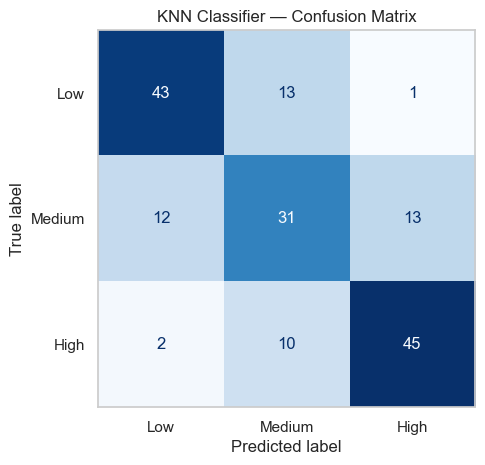

In [31]:
# Owner: Member 3
knn_clf_grid = GridSearchCV(KNeighborsClassifier(), param_grid={"n_neighbors": [3, 5, 7, 9, 15]},
                             cv=5, scoring="f1_weighted")
knn_clf_grid.fit(X_clf_train_s, y_clf_train)
print("Best KNN Classifier k:", knn_clf_grid.best_params_)
knn_clf = evaluate_classifier("KNN Classifier",
                               KNeighborsClassifier(n_neighbors=knn_clf_grid.best_params_["n_neighbors"]),
                               X_clf_train_s, X_clf_test_s, y_clf_train, y_clf_test)

**2b. KNN — comparing distance metrics** *(added in Review 2 to cover the note "discuss distance metrics")*. Same best `k`, three different distance definitions, compared by 5-fold CV weighted F1 on the training set only. `# Owner: Member 3`

In [32]:
# Owner: Member 3
best_k = knn_clf_grid.best_params_["n_neighbors"]
for metric in ["euclidean", "manhattan", "chebyshev"]:
    cv_f1 = cross_val_score(KNeighborsClassifier(n_neighbors=best_k, metric=metric),
                            X_clf_train_s, y_clf_train, cv=5, scoring="f1_weighted")
    print(f"k={best_k}, metric={metric:<9}: 5-fold CV weighted F1 = {cv_f1.mean():.3f} (+/- {cv_f1.std():.3f})")

k=3, metric=euclidean: 5-fold CV weighted F1 = 0.673 (+/- 0.038)
k=3, metric=manhattan: 5-fold CV weighted F1 = 0.679 (+/- 0.040)
k=3, metric=chebyshev: 5-fold CV weighted F1 = 0.661 (+/- 0.032)


**Observation:** _[Fill in: which distance metric works best here and why might that be (e.g. Manhattan is less sensitive to one large difference in a single feature)?]_

**3. Naive Bayes (Gaussian)** — assumes conditional independence between features given the class. `# Owner: Member 3`

Gaussian Naive Bayes: Accuracy=0.665  Precision=0.674  Recall=0.665  Weighted F1=0.634  ROC-AUC(OvR)=0.873


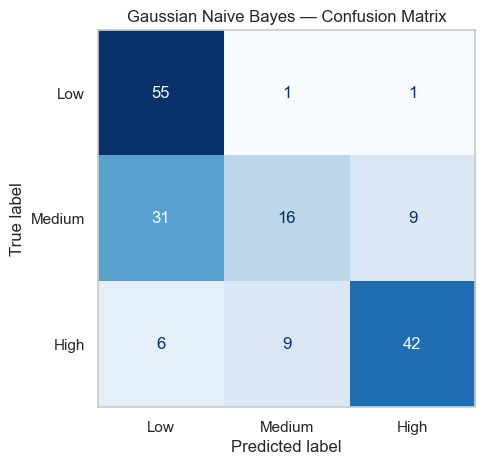

In [33]:
# Owner: Member 3
nb_clf = evaluate_classifier("Gaussian Naive Bayes", GaussianNB(),
                              X_clf_train_s, X_clf_test_s, y_clf_train, y_clf_test)

**3b. Naive Bayes — conditional-independence assumption** *(added in Review 2)*. Gaussian NB assumes every feature is independent of every other feature **within a class**. The heatmap below shows the feature correlations inside the training rows of each class; strong off-diagonal values mean the assumption is violated. `# Owner: Member 3`

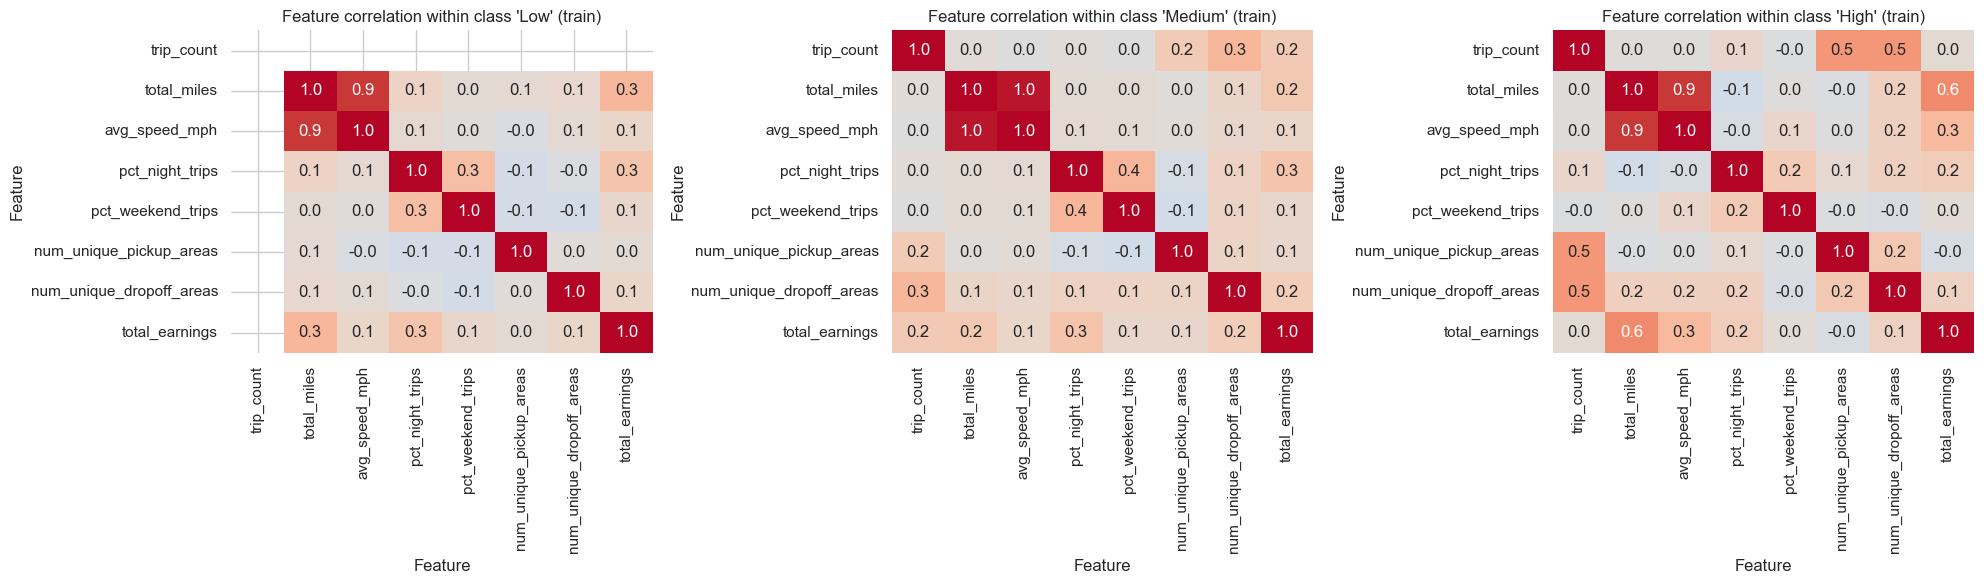

In [34]:
# Owner: Member 3
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, cls in zip(axes, CLASS_ORDER):
    within = X_clf_train_raw.loc[y_clf_train == cls, clf_numeric_features].corr()
    sns.heatmap(within, ax=ax, cmap="coolwarm", vmin=-1, vmax=1, annot=True, fmt=".1f", cbar=False)
    ax.set_title(f"Feature correlation within class '{cls}' (train)")
    ax.set_xlabel("Feature")
    ax.set_ylabel("Feature")
plt.tight_layout()
plt.savefig("clf_naive_bayes_within_class_correlation.png", bbox_inches="tight")
plt.show()

**Observation:** _[Fill in: which feature pairs are strongly correlated inside a class (e.g. trip_count vs total_miles)? How does that explain Gaussian NB's lower score?]_

**4. Decision Tree Classifier** — tune `max_depth`. `# Owner: Member 3`

Best Decision Tree Classifier max_depth: {'max_depth': 8}
Decision Tree Classifier: Accuracy=0.712  Precision=0.704  Recall=0.712  Weighted F1=0.706  ROC-AUC(OvR)=0.805


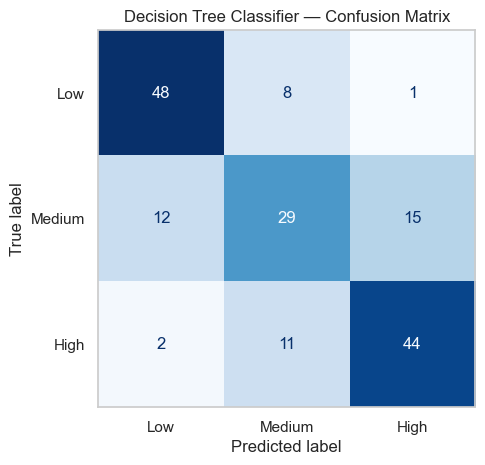

In [35]:
# Owner: Member 3
dt_clf_grid = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                            param_grid={"max_depth": [3, 5, 8, 12, None]}, cv=5, scoring="f1_weighted")
dt_clf_grid.fit(X_clf_train_s, y_clf_train)
print("Best Decision Tree Classifier max_depth:", dt_clf_grid.best_params_)
dt_clf = evaluate_classifier("Decision Tree Classifier",
                              DecisionTreeClassifier(max_depth=dt_clf_grid.best_params_["max_depth"], random_state=RANDOM_STATE),
                              X_clf_train_s, X_clf_test_s, y_clf_train, y_clf_test)

**4b. Decision Tree — visualising the tree** *(added in Review 2 to cover the note "visualise the tree")*. Only the top 3 levels are drawn so the plot stays readable; values shown are on the scaled features. `# Owner: Member 3`

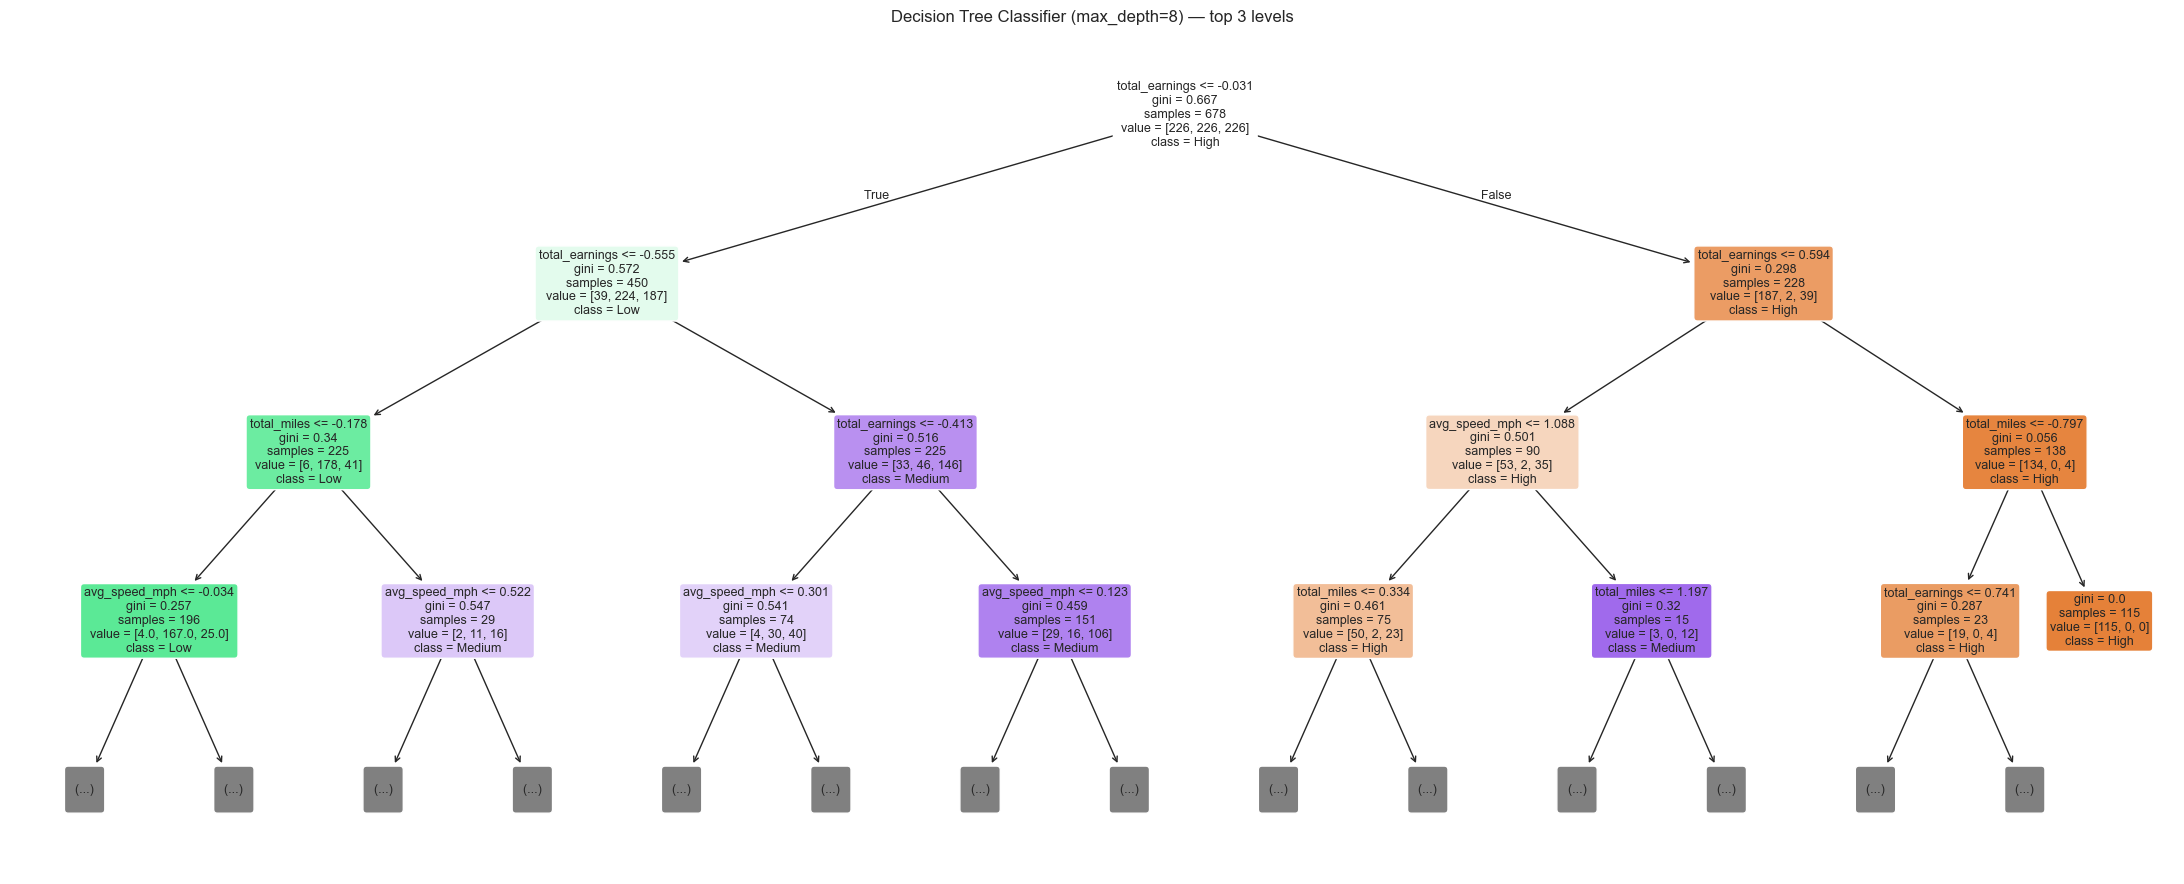

In [36]:
# Owner: Member 3
plt.figure(figsize=(22, 9))
plot_tree(dt_clf, feature_names=clf_features, class_names=list(dt_clf.classes_),
          max_depth=3, filled=True, rounded=True, fontsize=9)
plt.title(f"Decision Tree Classifier (max_depth={dt_clf_grid.best_params_['max_depth']}) — top 3 levels")
plt.tight_layout()
plt.savefig("clf_decision_tree_structure.png", bbox_inches="tight")
plt.show()

**5. Support Vector Machine (SVC)** — tune `C` and `kernel`; features scaled. `# Owner: Member 3`

Best SVC params: {'C': 10, 'kernel': 'linear'}
Support Vector Machine: Accuracy=0.818  Precision=0.818  Recall=0.818  Weighted F1=0.818  ROC-AUC(OvR)=0.949


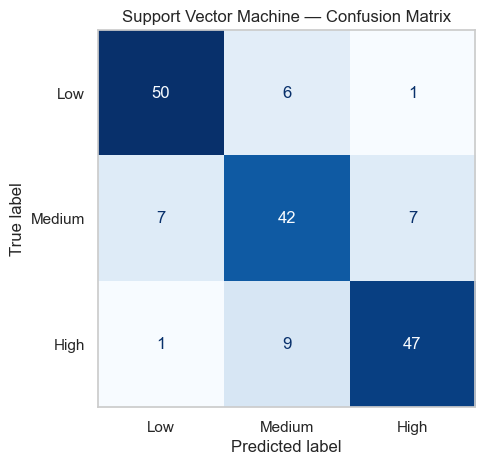

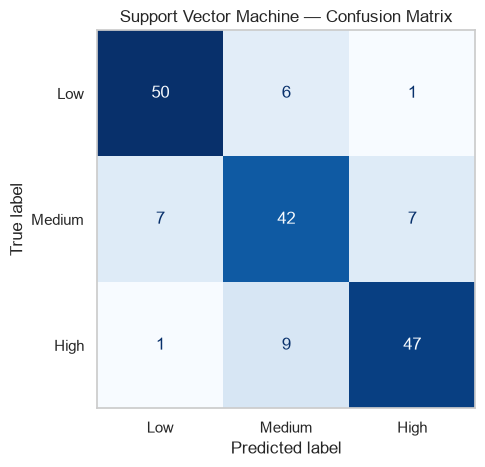

In [37]:
# Owner: Member 3
svc_grid = GridSearchCV(SVC(random_state=RANDOM_STATE), param_grid={"C": [1, 10, 100], "kernel": ["linear", "rbf"]},
                         cv=5, scoring="f1_weighted")
svc_grid.fit(X_clf_train_s, y_clf_train)
print("Best SVC params:", svc_grid.best_params_)
# Review 2: probability=True lets us compute ROC-AUC (OvR). SVC.predict() is unaffected by it.
svc_clf = evaluate_classifier("Support Vector Machine",
                               SVC(**svc_grid.best_params_, probability=True, random_state=RANDOM_STATE),
                               X_clf_train_s, X_clf_test_s, y_clf_train, y_clf_test)

### D2. Preliminary comparison table (Part A)

In [38]:
clf_comparison = pd.DataFrame(clf_results).sort_values("Weighted F1", ascending=False).reset_index(drop=True)
print(clf_comparison.to_string(index=False))
clf_comparison

               Algorithm  Accuracy  Precision (weighted)  Recall (weighted)  Weighted F1  ROC-AUC (OvR)
  Support Vector Machine  0.817647              0.818295           0.817647     0.817840       0.948584
     Logistic Regression  0.800000              0.799869           0.800000     0.799761       0.939788
Decision Tree Classifier  0.711765              0.704485           0.711765     0.706387       0.805381
          KNN Classifier  0.700000              0.697781           0.700000     0.698752       0.849723
    Gaussian Naive Bayes  0.664706              0.673977           0.664706     0.634475       0.873328


,Algorithm,Accuracy,Precision (weighted),Recall (weighted),Weighted F1,ROC-AUC (OvR)
0,Support Vector Machine,0.817647,0.818295,0.817647,0.817840,0.948584
1,Logistic Regression,0.800000,0.799869,0.800000,0.799761,0.939788
2,Decision Tree Classifier,0.711765,0.704485,0.711765,0.706387,0.805381
3,KNN Classifier,0.700000,0.697781,0.700000,0.698752,0.849723
4,Gaussian Naive Bayes,0.664706,0.673977,0.664706,0.634475,0.873328


## Section E — Classification Track, Part B (5 algorithms) — Review 2

Same dataset, same features, same stratified 80:20 split (`X_clf_train_s` / `X_clf_test_s`) and the same
`evaluate_classifier` helper as Part A, so all 10 algorithms are directly comparable.
Every grid search uses **5-fold CV on the training split only** (the test split is never used for tuning).
For each model we also fit an untuned (default) version, so the effect of tuning is visible.

### Member 3 — Classification algorithms 6–10

In [39]:
tuning_log = []  # one row per tuned Part B model: default vs tuned weighted F1 on the test set

def log_tuning(name, default_model, tuned_name):
    """Fit an untuned (default-parameter) copy and record its test F1 next to the tuned model's."""
    default_model.fit(X_clf_train_s, y_clf_train)
    f1_default = f1_score(y_clf_test, default_model.predict(X_clf_test_s), average="weighted")
    f1_tuned = f1_score(y_clf_test, fitted_clf_models[tuned_name][1], average="weighted")
    tuning_log.append({"Algorithm": tuned_name, "Weighted F1 (default params)": f1_default,
                       "Weighted F1 (tuned)": f1_tuned, "Change": f1_tuned - f1_default})
    print(f"Tuning effect for {tuned_name}: weighted F1 {f1_default:.4f} (default) -> {f1_tuned:.4f} (tuned)")

**6. Random Forest Classifier** — tune `n_estimators` (and `max_depth`); show feature importance. `# Owner: Member 3`

Best Random Forest Classifier params: {'max_depth': 8, 'n_estimators': 200}
Random Forest Classifier: Accuracy=0.747  Precision=0.742  Recall=0.747  Weighted F1=0.743  ROC-AUC(OvR)=0.923


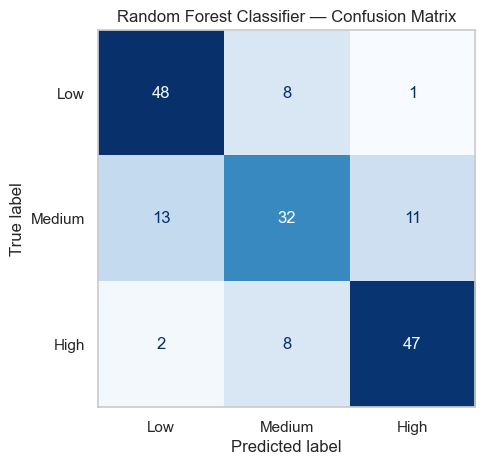

Tuning effect for Random Forest Classifier: weighted F1 0.7406 (default) -> 0.7427 (tuned)


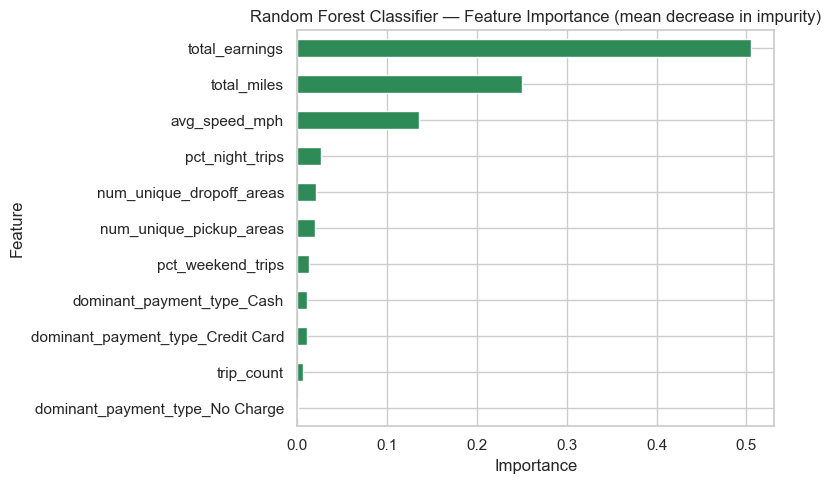

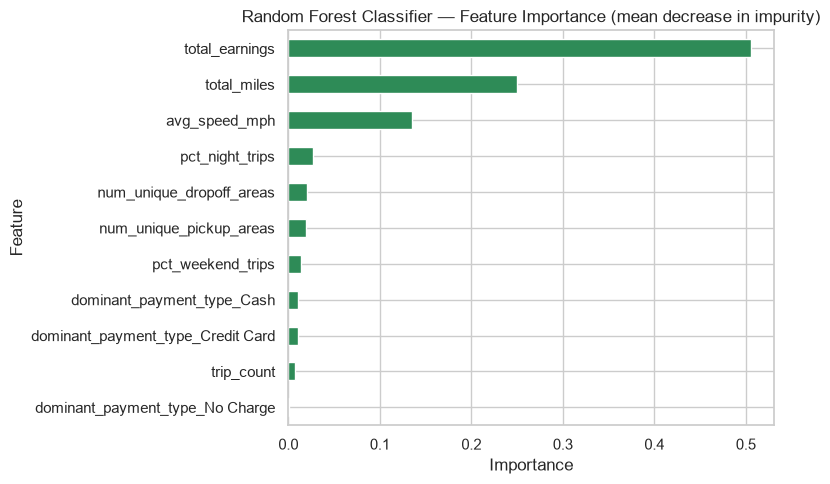

In [40]:
# Owner: Member 3
rf_clf_grid = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
                           param_grid={"n_estimators": [100, 200, 400], "max_depth": [None, 8, 12]},
                           cv=5, scoring="f1_weighted")
rf_clf_grid.fit(X_clf_train_s, y_clf_train)
print("Best Random Forest Classifier params:", rf_clf_grid.best_params_)
rf_clf = evaluate_classifier("Random Forest Classifier",
                             RandomForestClassifier(**rf_clf_grid.best_params_, random_state=RANDOM_STATE, n_jobs=-1),
                             X_clf_train_s, X_clf_test_s, y_clf_train, y_clf_test)
log_tuning("Random Forest Classifier", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), "Random Forest Classifier")

plt.figure(figsize=(8, 5))
pd.Series(rf_clf.feature_importances_, index=clf_features).sort_values().plot(kind="barh", color="seagreen")
plt.title("Random Forest Classifier — Feature Importance (mean decrease in impurity)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("clf_random_forest_feature_importance.png", bbox_inches="tight")
plt.show()

**Observation:** _[Fill in: which features matter most for predicting burnout risk? Does this agree with the Logistic Regression odds ratios?]_

**7. AdaBoost Classifier** — tune `n_estimators` and `learning_rate` (base learner: depth-1 decision stump, the sklearn default). `# Owner: Member 3`

Best AdaBoost params: {'learning_rate': 1.0, 'n_estimators': 200}
AdaBoost Classifier: Accuracy=0.753  Precision=0.760  Recall=0.753  Weighted F1=0.755  ROC-AUC(OvR)=0.889


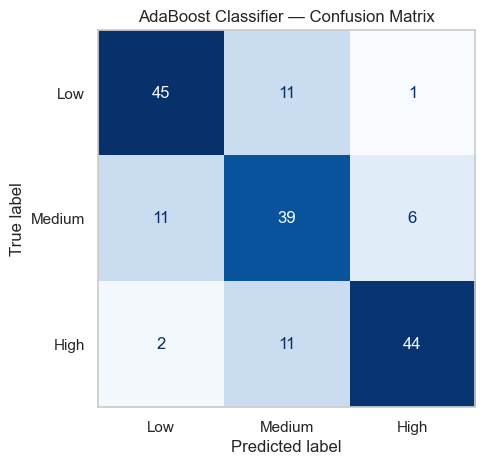

Tuning effect for AdaBoost Classifier: weighted F1 0.7555 (default) -> 0.7552 (tuned)


Tuning effect for AdaBoost Classifier: weighted F1 0.7555 (default) -> 0.7552 (tuned)


In [41]:
# Owner: Member 3
ada_grid = GridSearchCV(AdaBoostClassifier(random_state=RANDOM_STATE),
                        param_grid={"n_estimators": [50, 100, 200], "learning_rate": [0.01, 0.1, 0.5, 1.0]},
                        cv=5, scoring="f1_weighted")
ada_grid.fit(X_clf_train_s, y_clf_train)
print("Best AdaBoost params:", ada_grid.best_params_)
ada_clf = evaluate_classifier("AdaBoost Classifier",
                              AdaBoostClassifier(**ada_grid.best_params_, random_state=RANDOM_STATE),
                              X_clf_train_s, X_clf_test_s, y_clf_train, y_clf_test)
log_tuning("AdaBoost Classifier", AdaBoostClassifier(random_state=RANDOM_STATE), "AdaBoost Classifier")

**8. Gradient Boosting Classifier** — sklearn GBM; tune `learning_rate` and `n_estimators`. `# Owner: Member 3`

Best Gradient Boosting Classifier params: {'learning_rate': 0.1, 'n_estimators': 100}
Gradient Boosting Classifier: Accuracy=0.788  Precision=0.788  Recall=0.788  Weighted F1=0.788  ROC-AUC(OvR)=0.938


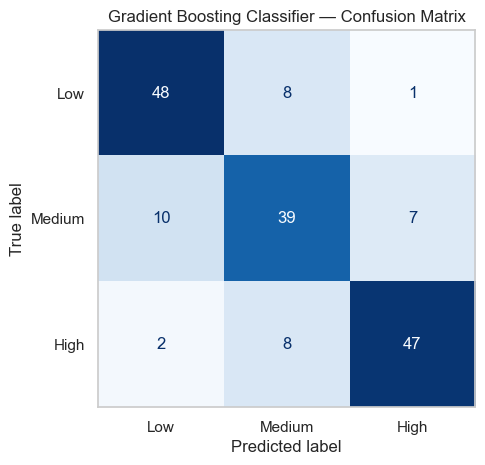

Tuning effect for Gradient Boosting Classifier: weighted F1 0.7880 (default) -> 0.7880 (tuned)


Tuning effect for Gradient Boosting Classifier: weighted F1 0.7880 (default) -> 0.7880 (tuned)


In [42]:
# Owner: Member 3
gb_clf_grid = GridSearchCV(GradientBoostingClassifier(random_state=RANDOM_STATE),
                           param_grid={"learning_rate": [0.01, 0.05, 0.1, 0.2], "n_estimators": [100, 200]},
                           cv=5, scoring="f1_weighted")
gb_clf_grid.fit(X_clf_train_s, y_clf_train)
print("Best Gradient Boosting Classifier params:", gb_clf_grid.best_params_)
gb_clf = evaluate_classifier("Gradient Boosting Classifier",
                             GradientBoostingClassifier(**gb_clf_grid.best_params_, random_state=RANDOM_STATE),
                             X_clf_train_s, X_clf_test_s, y_clf_train, y_clf_test)
log_tuning("Gradient Boosting Classifier", GradientBoostingClassifier(random_state=RANDOM_STATE), "Gradient Boosting Classifier")

**9. Bagging Classifier** — Decision Tree as the base estimator; tune `n_estimators` and `max_samples`. `# Owner: Member 3`

Best Bagging params: {'max_samples': 1.0, 'n_estimators': 100}
Bagging Classifier (Decision Tree): Accuracy=0.729  Precision=0.730  Recall=0.729  Weighted F1=0.730  ROC-AUC(OvR)=0.912


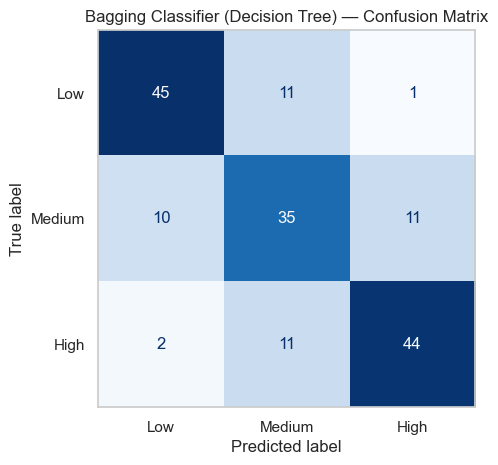

Tuning effect for Bagging Classifier (Decision Tree): weighted F1 0.7241 (default) -> 0.7299 (tuned)


Tuning effect for Bagging Classifier (Decision Tree): weighted F1 0.7241 (default) -> 0.7299 (tuned)


In [43]:
# Owner: Member 3
bag_grid = GridSearchCV(BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                                          random_state=RANDOM_STATE, n_jobs=-1),
                        param_grid={"n_estimators": [10, 50, 100], "max_samples": [0.5, 1.0]},
                        cv=5, scoring="f1_weighted")
bag_grid.fit(X_clf_train_s, y_clf_train)
print("Best Bagging params:", bag_grid.best_params_)
bag_clf = evaluate_classifier("Bagging Classifier (Decision Tree)",
                              BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                                                **bag_grid.best_params_, random_state=RANDOM_STATE, n_jobs=-1),
                              X_clf_train_s, X_clf_test_s, y_clf_train, y_clf_test)
log_tuning("Bagging Classifier (Decision Tree)",
           BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE), random_state=RANDOM_STATE, n_jobs=-1),
           "Bagging Classifier (Decision Tree)")

**10. MLP Classifier (Neural Network)** — tune `hidden_layer_sizes` and `activation`. Inputs are already standardised, which neural networks need to train well. `# Owner: Member 3`

Best MLP params: {'activation': 'relu', 'hidden_layer_sizes': (32,)}
MLP Classifier: Accuracy=0.806  Precision=0.807  Recall=0.806  Weighted F1=0.806  ROC-AUC(OvR)=0.933


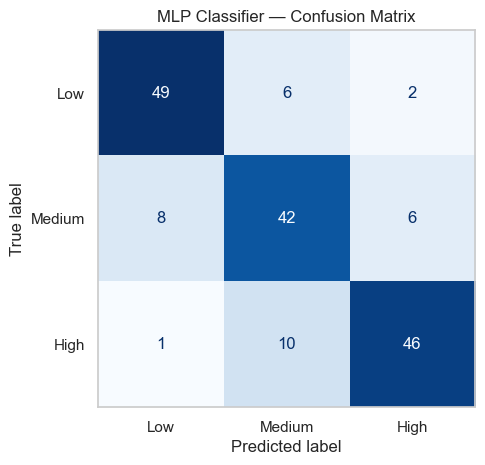

Tuning effect for MLP Classifier: weighted F1 0.8014 (default) -> 0.8064 (tuned)


Tuning effect for MLP Classifier: weighted F1 0.8014 (default) -> 0.8064 (tuned)


In [44]:
# Owner: Member 3
mlp_grid = GridSearchCV(MLPClassifier(max_iter=2000, random_state=RANDOM_STATE),
                        param_grid={"hidden_layer_sizes": [(32,), (64,), (64, 32)],
                                    "activation": ["relu", "tanh"]},
                        cv=5, scoring="f1_weighted")
mlp_grid.fit(X_clf_train_s, y_clf_train)
print("Best MLP params:", mlp_grid.best_params_)
mlp_clf = evaluate_classifier("MLP Classifier",
                              MLPClassifier(**mlp_grid.best_params_, max_iter=2000, random_state=RANDOM_STATE),
                              X_clf_train_s, X_clf_test_s, y_clf_train, y_clf_test)
log_tuning("MLP Classifier", MLPClassifier(max_iter=2000, random_state=RANDOM_STATE), "MLP Classifier")

### Effect of hyperparameter tuning on the Part B models (test-set weighted F1)

In [45]:
tuning_table = pd.DataFrame(tuning_log)
tuning_table.round(4)

,Algorithm,Weighted F1 (default params),Weighted F1 (tuned),Change
0,Random Forest Classifier,0.7406,0.7427,0.0021
1,AdaBoost Classifier,0.7555,0.7552,-0.0003
2,Gradient Boosting Classifier,0.7880,0.7880,0.0000
3,Bagging Classifier (Decision Tree),0.7241,0.7299,0.0058
4,MLP Classifier,0.8014,0.8064,0.0050


**Observation:** _[Fill in: for which models did tuning help, and for which did it make no difference or slightly hurt on the test set? Why can CV-optimal parameters still score a little lower on one particular test split?]_

## Section F — Consolidated 10-algorithm classification comparison (Review 2 — D6 / rubric A2)

In [46]:
clf_full_comparison = (pd.DataFrame(clf_results)
                       .sort_values(["Weighted F1", "ROC-AUC (OvR)"], ascending=False)
                       .reset_index(drop=True))
clf_full_comparison.index = clf_full_comparison.index + 1   # rank starting at 1
clf_full_comparison.index.name = "Rank"
assert len(clf_full_comparison) == 10, "Expected exactly 10 classification algorithms in the table"
clf_full_comparison.to_csv("classification_comparison_10_models.csv")
clf_full_comparison.round(4)

,Algorithm,Accuracy,Precision (weighted),Recall (weighted),Weighted F1,ROC-AUC (OvR)
Rank,,,,,,
1,Support Vector Machine,0.8176,0.8183,0.8176,0.8178,0.9486
2,MLP Classifier,0.8059,0.8074,0.8059,0.8064,0.9326
3,Logistic Regression,0.8000,0.7999,0.8000,0.7998,0.9398
4,Gradient Boosting Classifier,0.7882,0.7883,0.7882,0.7880,0.9380
5,AdaBoost Classifier,0.7529,0.7600,0.7529,0.7552,0.8886
6,Random Forest Classifier,0.7471,0.7422,0.7471,0.7427,0.9226
7,Bagging Classifier (Decision Tree),0.7294,0.7304,0.7294,0.7299,0.9124
8,Decision Tree Classifier,0.7118,0.7045,0.7118,0.7064,0.8054
9,KNN Classifier,0.7000,0.6978,0.7000,0.6988,0.8497


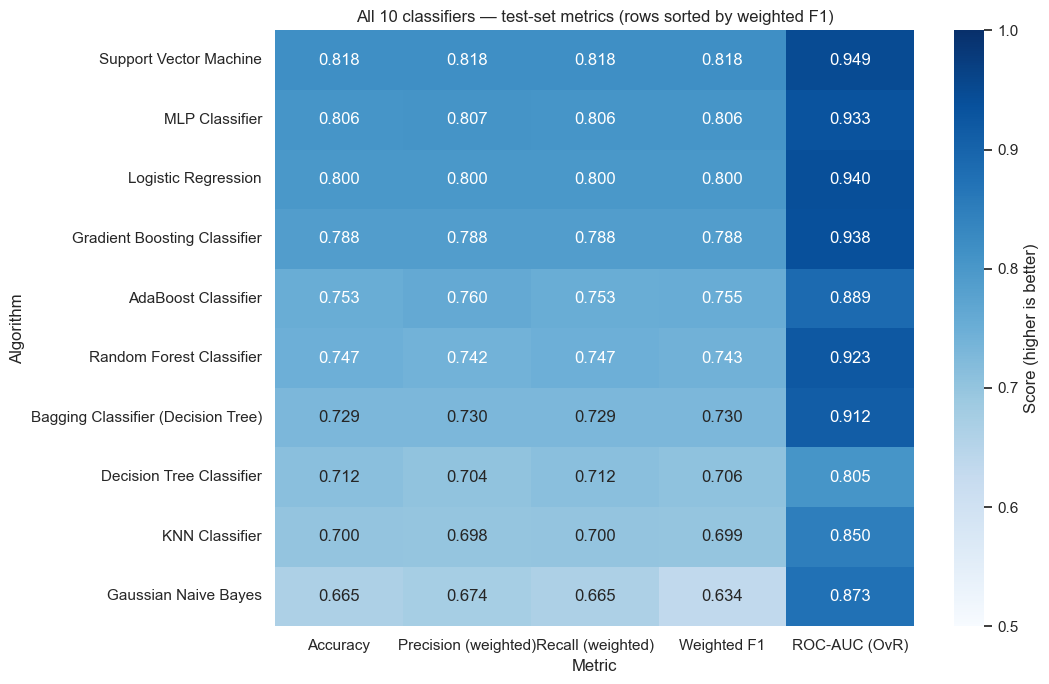

In [47]:
metric_cols = ["Accuracy", "Precision (weighted)", "Recall (weighted)", "Weighted F1", "ROC-AUC (OvR)"]
plot_df = clf_full_comparison.set_index("Algorithm")[metric_cols]

fig, ax = plt.subplots(figsize=(11, 7))
sns.heatmap(plot_df, annot=True, fmt=".3f", cmap="Blues", vmin=0.5, vmax=1.0,
            cbar_kws={"label": "Score (higher is better)"}, ax=ax)
ax.set_title("All 10 classifiers — test-set metrics (rows sorted by weighted F1)")
ax.set_xlabel("Metric")
ax.set_ylabel("Algorithm")
plt.tight_layout()
plt.savefig("clf_all_models_metric_comparison.png", bbox_inches="tight")
plt.show()

**Observation:** _[Fill in: which family (linear, distance-based, single tree, ensembles, neural net) does best on this data? Is the gap between the top models large or within noise (compare with the CV standard deviations below)?]_

### F2. 5-fold cross-validation for the two best-performing models (guideline 7.2)
A single 170-row test split is noisy, so the top 2 models by test weighted F1 are re-checked with stratified
5-fold CV on the **training split** (same hyperparameters as in the table).

In [48]:
cv_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
top2_clf = clf_full_comparison["Algorithm"].iloc[:2].tolist()

cv_rows = []
for name in top2_clf:
    model_copy = clone(fitted_clf_models[name][0])   # same hyperparameters, unfitted
    scores = cross_val_score(model_copy, X_clf_train_s, y_clf_train, cv=cv_splitter, scoring="f1_weighted")
    cv_rows.append({"Algorithm": name, "CV weighted F1 (mean)": scores.mean(), "CV weighted F1 (std)": scores.std(),
                    "Test weighted F1": clf_full_comparison.set_index("Algorithm").loc[name, "Weighted F1"]})
clf_cv_table = pd.DataFrame(cv_rows)
clf_cv_table.round(4)

,Algorithm,CV weighted F1 (mean),CV weighted F1 (std),Test weighted F1
0,Support Vector Machine,0.8465,0.0208,0.8178
1,MLP Classifier,0.8075,0.0334,0.8064


### F3. Final model selection + hyperparameter tuning (rubric A3)
**Selection rule (decided before looking at the result):** of the two models above, the one with the higher
**mean 5-fold CV weighted F1** is selected, because CV uses 5 different validation splits and is therefore a more
reliable estimate than the single test split. The selected model is then tuned with a wider `GridSearchCV`
whose grid **includes the sklearn default settings**, and default vs. tuned scores are compared on both CV and
the untouched test set.

In [49]:
final_name = clf_cv_table.sort_values("CV weighted F1 (mean)", ascending=False)["Algorithm"].iloc[0]
print("Selected final model:", final_name)

# Default (untuned) estimator + a wider search grid for every algorithm that could be selected.
final_search_spaces = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
                            {"C": [0.01, 0.1, 1, 10, 100], "class_weight": [None, "balanced"]}),
    "KNN Classifier": (KNeighborsClassifier(),
                       {"n_neighbors": [3, 5, 7, 9, 15, 25], "weights": ["uniform", "distance"],
                        "metric": ["euclidean", "manhattan"]}),
    "Gaussian Naive Bayes": (GaussianNB(), {"var_smoothing": [1e-11, 1e-9, 1e-7, 1e-5, 1e-3]}),
    "Decision Tree Classifier": (DecisionTreeClassifier(random_state=RANDOM_STATE),
                                 {"max_depth": [3, 5, 8, 12, None], "min_samples_leaf": [1, 5, 10],
                                  "criterion": ["gini", "entropy"]}),
    "Support Vector Machine": (SVC(probability=True, random_state=RANDOM_STATE),
                               [{"kernel": ["linear"], "C": [0.1, 1, 10, 100]},
                                {"kernel": ["rbf"], "C": [0.1, 1, 10, 100], "gamma": ["scale", 0.01, 0.1]}]),
    "Random Forest Classifier": (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
                                 {"n_estimators": [100, 200, 400], "max_depth": [None, 8, 12],
                                  "min_samples_leaf": [1, 3], "max_features": ["sqrt", None]}),
    "AdaBoost Classifier": (AdaBoostClassifier(random_state=RANDOM_STATE),
                            {"n_estimators": [50, 100, 200, 400], "learning_rate": [0.05, 0.1, 0.5, 1.0]}),
    "Gradient Boosting Classifier": (GradientBoostingClassifier(random_state=RANDOM_STATE),
                                     {"learning_rate": [0.05, 0.1, 0.2], "n_estimators": [100, 200],
                                      "max_depth": [2, 3, 4], "subsample": [0.8, 1.0]}),
    "Bagging Classifier (Decision Tree)": (BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                                                             random_state=RANDOM_STATE, n_jobs=-1),
                                           {"n_estimators": [10, 50, 100, 200], "max_samples": [0.5, 0.8, 1.0],
                                            "max_features": [0.7, 1.0]}),
    "MLP Classifier": (MLPClassifier(max_iter=2000, random_state=RANDOM_STATE),
                       {"hidden_layer_sizes": [(32,), (64,), (100,), (64, 32)],
                        "activation": ["relu", "tanh"], "alpha": [0.0001, 0.001, 0.01]}),
}
default_model, search_grid = final_search_spaces[final_name]

# --- Before tuning: sklearn default hyperparameters
default_cv = cross_val_score(clone(default_model), X_clf_train_s, y_clf_train, cv=cv_splitter, scoring="f1_weighted")
default_fitted = clone(default_model).fit(X_clf_train_s, y_clf_train)

# --- Tuning: GridSearchCV on the training split only
final_search = GridSearchCV(clone(default_model), search_grid, cv=cv_splitter, scoring="f1_weighted", n_jobs=-1)
final_search.fit(X_clf_train_s, y_clf_train)
final_model = final_search.best_estimator_
print("Best hyperparameters found:", final_search.best_params_)

def test_metrics(model):
    preds = model.predict(X_clf_test_s)
    proba = model.predict_proba(X_clf_test_s)
    return {"Accuracy": accuracy_score(y_clf_test, preds),
            "Precision (weighted)": precision_score(y_clf_test, preds, average="weighted", zero_division=0),
            "Recall (weighted)": recall_score(y_clf_test, preds, average="weighted", zero_division=0),
            "Weighted F1": f1_score(y_clf_test, preds, average="weighted"),
            "ROC-AUC (OvR)": roc_auc_score(y_clf_test, proba, multi_class="ovr", average="weighted", labels=model.classes_)}

tuning_comparison = pd.DataFrame({
    "Default params": {"CV weighted F1 (5-fold)": default_cv.mean(), **test_metrics(default_fitted)},
    "Tuned (GridSearchCV)": {"CV weighted F1 (5-fold)": final_search.best_score_, **test_metrics(final_model)},
})
tuning_comparison["Change"] = tuning_comparison["Tuned (GridSearchCV)"] - tuning_comparison["Default params"]
print(f"\n{final_name}: default vs tuned")
tuning_comparison.round(4)

Selected final model: Support Vector Machine
Best hyperparameters found: {'C': 100, 'kernel': 'linear'}

Support Vector Machine: default vs tuned


,Default params,Tuned (GridSearchCV),Change
CV weighted F1 (5-fold),0.7271,0.8495,0.1224
Accuracy,0.7529,0.8176,0.0647
Precision (weighted),0.7613,0.8168,0.0555
Recall (weighted),0.7529,0.8176,0.0647
Weighted F1,0.7555,0.8171,0.0616
ROC-AUC (OvR),0.8987,0.9496,0.0509


,Default params,Tuned (GridSearchCV),Change
CV weighted F1 (5-fold),0.7271,0.8495,0.1224
Accuracy,0.7529,0.8176,0.0647
Precision (weighted),0.7613,0.8168,0.0555
Recall (weighted),0.7529,0.8176,0.0647
Weighted F1,0.7555,0.8171,0.0616
ROC-AUC (OvR),0.8987,0.9496,0.0509


In [50]:
improved = tuning_comparison.index[tuning_comparison["Change"] > 0].tolist()
print(f"Metrics improved by tuning {final_name}:", improved if improved else "none")
for metric in improved:
    row = tuning_comparison.loc[metric]
    print(f"  {metric}: {row['Default params']:.4f} -> {row['Tuned (GridSearchCV)']:.4f} (+{row['Change']:.4f})")

print("\nClassification report — final tuned model (test set):")
print(classification_report(y_clf_test, final_model.predict(X_clf_test_s), labels=CLASS_ORDER, digits=3))

Metrics improved by tuning Support Vector Machine: ['CV weighted F1 (5-fold)', 'Accuracy', 'Precision (weighted)', 'Recall (weighted)', 'Weighted F1', 'ROC-AUC (OvR)']
  CV weighted F1 (5-fold): 0.7271 -> 0.8495 (+0.1224)
  Accuracy: 0.7529 -> 0.8176 (+0.0647)
  Precision (weighted): 0.7613 -> 0.8168 (+0.0555)
  Recall (weighted): 0.7529 -> 0.8176 (+0.0647)
  Weighted F1: 0.7555 -> 0.8171 (+0.0616)
  ROC-AUC (OvR): 0.8987 -> 0.9496 (+0.0509)

Classification report — final tuned model (test set):
              precision    recall  f1-score   support

         Low      0.864     0.895     0.879        57
      Medium      0.745     0.732     0.739        56
        High      0.839     0.825     0.832        57

    accuracy                          0.818       170
   macro avg      0.816     0.817     0.817       170
weighted avg      0.817     0.818     0.817       170



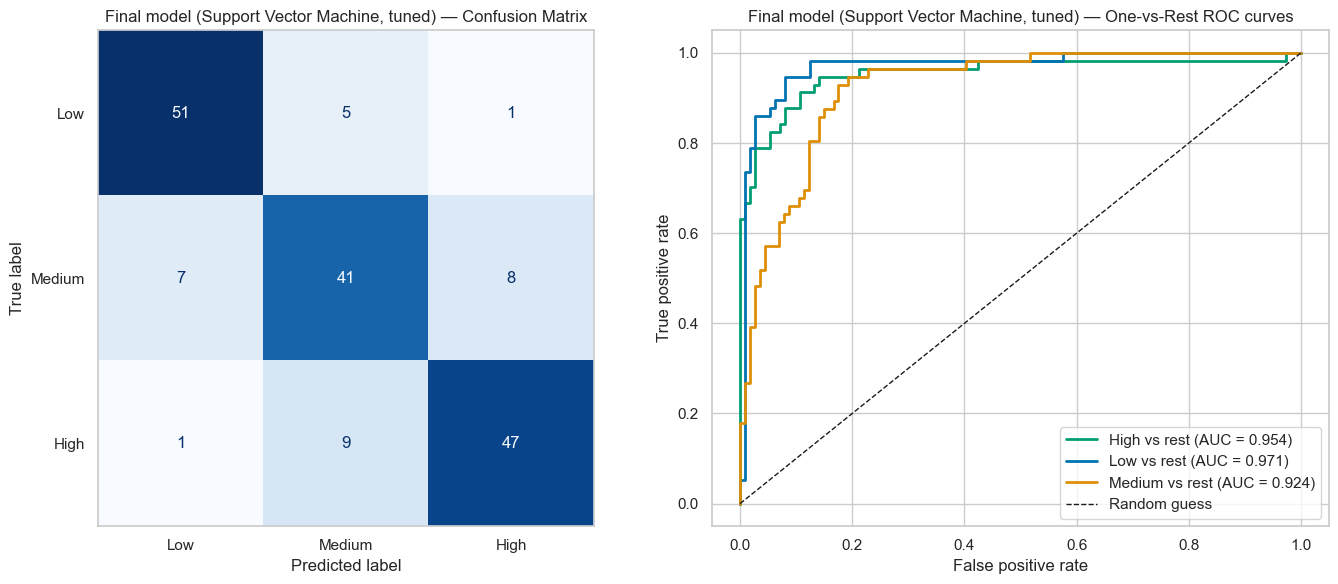

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Confusion matrix of the final tuned model
ConfusionMatrixDisplay.from_estimator(final_model, X_clf_test_s, y_clf_test, labels=CLASS_ORDER,
                                      cmap="Blues", colorbar=False, ax=axes[0])
axes[0].grid(False)
axes[0].set_title(f"Final model ({final_name}, tuned) — Confusion Matrix")

# One-vs-Rest ROC curve for each class
proba_final = final_model.predict_proba(X_clf_test_s)
y_test_bin = label_binarize(y_clf_test, classes=list(final_model.classes_))
colors = dict(zip(CLASS_ORDER, sns.color_palette("colorblind", 3)))
for idx, cls in enumerate(final_model.classes_):
    fpr, tpr, _ = roc_curve(y_test_bin[:, idx], proba_final[:, idx])
    auc_cls = roc_auc_score(y_test_bin[:, idx], proba_final[:, idx])
    axes[1].plot(fpr, tpr, lw=2, color=colors[cls], label=f"{cls} vs rest (AUC = {auc_cls:.3f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="Random guess")
axes[1].set_title(f"Final model ({final_name}, tuned) — One-vs-Rest ROC curves")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.savefig("clf_final_model_confusion_and_roc.png", bbox_inches="tight")
plt.show()

**Final model justification (write this yourselves — guideline 7.5 does not allow AI-written interpretation):**
_[Fill in, using the tables above: (1) which model you selected and its CV/test scores, (2) why CV was used to choose
between the top two, (3) what tuning changed and which metric(s) improved, (4) any trade-off you accepted —
e.g. interpretability vs. accuracy, training time, or which class is most often confused and why.]_

## Section G — Save trained models for the GUI (bonus)
The Streamlit app in `app/` loads these files. Each file stores the **exact fitted** scaler and encoder from
Section B2 (fitted on the training split only) plus the model, so the app transforms user input identically.

In [52]:
MODELS_DIR = Path("../models") if Path("../models").exists() else Path("models")
MODELS_DIR.mkdir(exist_ok=True)

def input_ranges(frame, cols):
    """Min / median / max of each raw training feature — used for the app's input widgets."""
    return {c: {"min": float(frame[c].min()), "median": float(frame[c].median()), "max": float(frame[c].max())} for c in cols}

burnout_bundle = {
    "model": final_model, "model_name": final_name, "scaler": scaler_clf, "encoder": ohe_clf,
    "numeric_features": clf_numeric_features, "categorical_features": clf_categorical_features,
    "feature_order": clf_features, "class_order": CLASS_ORDER,
    "payment_types": list(ohe_clf.categories_[0]),
    "input_ranges": input_ranges(X_clf_train_raw, clf_numeric_features),
    "test_metrics": test_metrics(final_model),
}
joblib.dump(burnout_bundle, MODELS_DIR / "burnout_classifier.pkl")

best_reg_name = reg_comparison.iloc[0]["Algorithm"]
if best_reg_name not in fitted_reg_models or best_reg_name.startswith("Polynomial"):
    best_reg_name = "Random Forest Regressor"   # needs a plain estimator on the scaled features
earnings_bundle = {
    "model": fitted_reg_models[best_reg_name][0], "model_name": best_reg_name,
    "scaler": scaler_reg, "encoder": ohe_reg,
    "numeric_features": reg_numeric_features, "categorical_features": reg_categorical_features,
    "feature_order": reg_features, "payment_types": list(ohe_reg.categories_[0]),
    "input_ranges": input_ranges(X_reg_train_raw, reg_numeric_features),
    "test_metrics": reg_comparison.set_index("Algorithm").loc[best_reg_name, ["R2", "RMSE", "MAE"]].to_dict(),
}
joblib.dump(earnings_bundle, MODELS_DIR / "earnings_regressor.pkl")

# Quick self-check: reload and reproduce the notebook's test predictions exactly
reloaded = joblib.load(MODELS_DIR / "burnout_classifier.pkl")
X_check = np.hstack([reloaded["scaler"].transform(X_clf_test_raw[clf_numeric_features]),
                     reloaded["encoder"].transform(X_clf_test_raw[clf_categorical_features])])
assert (reloaded["model"].predict(pd.DataFrame(X_check, columns=clf_features)) == final_model.predict(X_clf_test_s)).all()
print("Saved:", MODELS_DIR / "burnout_classifier.pkl", "(", final_name, ") and",
      MODELS_DIR / "earnings_regressor.pkl", "(", best_reg_name, ") — reload check passed.")

Saved: ..\models\burnout_classifier.pkl ( Support Vector Machine ) and ..\models\earnings_regressor.pkl ( Random Forest Regressor ) — reload check passed.


## Review 1 — rubric compliance checklist (re-verified against the guidelines)

| Rubric item | Max | Where it's covered |
|---|---|---|
| Primary tools | — | Python 3, scikit-learn, Pandas, NumPy, Matplotlib, Seaborn — all imported/used in cell 2, no other ML library used |
| A1 Dataset loading & audit | 1 | Section A1 — shape, dtypes, missing counts, `trip_total`/categorical distributions |
| A2 EDA visualisations | 2 | Section A2 — 7 numeric distributions, 3 categorical distributions, pickup-hour distribution, correlation heatmap, target distribution, 2 scatter plots |
| A3 Insight commentary | 1 | `**Observation:**` markdown cell after every major visualisation |
| B1 Data cleaning | 1 | Section B1 — justified missing-value strategy, duplicate/outlier handling |
| B2 Encoding, scaling & splitting | 1 | Section B2 — `OneHotEncoder` + `StandardScaler` fit on train only; classification split stratified on `burnout_risk`, regression split stratified on binned `total_earnings` |
| B3 Feature engineering | 1 | Section B3 — `trip_speed_mph`, `pickup_hour`, `is_night`, `is_weekend`, driver-day aggregates, with written justification |
| C1 Regression implementation | 4 | Section C — all 10 algorithms, Members 1 & 2 |
| C2 Comparative evaluation | 2 | Section C2 — `reg_comparison` table, R2/RMSE/MAE, ranked |
| C3 Hyperparameter tuning | 2 | `GridSearchCV` on 8 of 10 models; explicit before/after R2 improvement printed for Ridge and Random Forest |
| C4 Visualisation | 1 | Residual + predicted-vs-actual plot for the **dynamically-selected** actual best model; Random Forest feature importance |
| D1 Classification Part A implementation | 2 | Section D — all 5 algorithms, Member 3 |
| D2 Evaluation | 1 | Accuracy, weighted F1, confusion matrix per algorithm + `clf_comparison` table |
| E1 Presentation quality | 1 | Markdown narrative links every step; ownership tags make individual accountability explicit for the viva |

**Not coverable by a notebook (handle separately, D2/D1 deliverables):**
- **D2 GitHub repository:** create the repo with the required structure (`README.md`, `requirements.txt`, `data/`, `notebooks/`, `models/`, `app/`) and commit incrementally — e.g. one commit per algorithm/section, authored by the actual member who wrote it, so authorship matches the ownership tags above. A single bulk commit gets zero on this criterion regardless of code quality.
- **Viva (5 marks):** not something code can prepare — each member should be ready to explain *any* cell, not just their own algorithms, since guideline 7.4 explicitly says the examiner may question anyone about any part.

**Before your review:** run all cells top-to-bottom with `chicago_taxi_sample.csv` in the same folder as the notebook, fill in every `**Observation:**` markdown cell with your own interpretation, and confirm no cell raises an error.

## Review 2 — rubric compliance checklist (classification part; clustering is in `clustering.ipynb`)

| Rubric item | Max | Where it's covered |
|---|---|---|
| A1 Part B implementation | 3 | Section E — Random Forest, AdaBoost, Gradient Boosting, Bagging (Decision Tree base), MLP, all on the same split/features as Part A |
| A2 Full comparison table | 1 | Section F — `clf_full_comparison`: all 10 models × Accuracy, Precision, Recall, F1 (weighted), ROC-AUC (OvR); confusion matrix per model above; saved as `classification_comparison_10_models.csv` |
| A3 Final model selection | 2 | Section F2 (5-fold CV of top 2) + F3 (CV-based selection rule, GridSearchCV, default-vs-tuned table, improved metrics printed) + your written justification |
| Algorithm notes | — | RF feature importance; AdaBoost `n_estimators`+`learning_rate`; sklearn GBM; Bagging with Decision Tree base; MLP `hidden_layer_sizes`+`activation`. Part A notes completed: odds ratios (1b), distance metrics (2b), NB independence check (3b), tree plot (4b) |
| 7.1 Reproducibility / leakage | — | `random_state=42` everywhere; scaler & encoder fitted on train only; all tuning via CV on train only |
| Bonus GUI | +1 | Section G saves `models/*.pkl`; Streamlit app in `app/app.py` |

**Before Review 2:** restart the kernel and *Run All*, then fill in every `**Observation:**` cell and the final-model justification in your own words.